# EDA intermedio del mercado inmobiliario

Este notebook conecta la limpieza estructural con el modelado. Cada bloque ejecutable tiene debajo una interpretación basada en sus resultados, para entender qué muestra, para qué sirve y qué decisión puede orientar.

No se eliminan observaciones automáticamente: el EDA diagnostica y documenta; la limpieza posterior debe justificarse.

## Alcance y fuente

Usamos `secondary_market_date_transformado.csv`, generado después de convertir `date_posted`, agregar `date_posted_year`, `date_posted_month` y calcular `building_age`. Todavía conserva las variables categóricas originales, por lo que es el punto correcto para hacer EDA.

La variable objetivo será `price_per_sqm`. `price_rub` se conserva para describir el dataset, pero se excluye de los predictores porque contiene información derivada del objetivo.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import statsmodels.api as sm

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda valor: f"{valor:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")

RUTA_EDA = Path("data_sets_transformados/secondary_market_date_transformado.csv")
RUTA_GRAFICOS = Path("eda_salidas")
RUTA_GRAFICOS.mkdir(exist_ok=True)

### Lectura del bloque de configuración

Este bloque no produce un hallazgo del dataset: prepara las librerías, fija el estilo de los gráficos y define las rutas. `RUTA_EDA` apunta al resultado de la limpieza estructural y `RUTA_GRAFICOS` conserva las figuras para revisarlas fuera del notebook.

In [2]:
# Cargamos el dataset producido por la limpieza estructural.
df = pd.read_csv(RUTA_EDA, parse_dates=["date_posted"])
df_original = df.copy()

print(f"Archivo: {RUTA_EDA}")
print(f"Filas: {df.shape[0]:,} | Columnas: {df.shape[1]:,}")
print(f"Memoria aproximada: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")
display(df.head())

Archivo: data_sets_transformados\secondary_market_date_transformado.csv
Filas: 50,000 | Columnas: 29
Memoria aproximada: 14.69 MB


,id,date_posted,district,okrug,lat,lon,total_area,living_area,kitchen_area,rooms,floor,total_floors,building_year,building_type,ceiling_height,has_balcony,renovation,metro_station,metro_line,metro_distance_min,metro_distance_type,to_center_km,price_rub,price_per_sqm,mortgage_rate_at_listing,seller_type,date_posted_year,date_posted_month,building_age
0,S000001,2024-11-23,Begovoy,SAO,55.795,37.555,71.000,46.500,6.100,2,19,25,1969,khrushchev,2.500,True,cosmetic,Sokol,Zamoskvoretskaya,18,transport,6.170,15739000,221700,23.500,agency,2024,11,55
1,S000002,2025-08-13,Sokolniki,VAO,55.797,37.689,79.600,52.800,10.800,3,2,25,2016,modern_panel,2.500,True,no_renovation,Sokolniki,Sokolnicheskaya,7,walk,6.400,19685000,247300,19.500,owner,2025,8,9
2,S000003,2022-05-06,Sosenskoye,NAO,55.549,37.431,74.000,42.200,8.900,2,6,9,2016,monolith,3.000,True,cosmetic,Polyanka,Serpukhovsko-Timiryazevskaya,102,transport,25.700,8621000,116400,12.000,owner,2022,5,6
3,S000004,2025-04-08,Sviblovo,SVAO,55.865,37.615,52.300,34.000,6.000,1,5,22,2012,monolith,2.500,True,euro,Sviblovo,Kaluzhsko-Rizhskaya,9,walk,12.320,14771000,282400,23.500,agency,2025,4,13
4,S000005,2023-07-16,Begovoy,SAO,55.794,37.546,62.200,38.300,13.100,2,12,12,2002,brick,2.500,True,cosmetic,Sapyornoye Pole,Bolshaya Koltsevaya,10,walk,6.470,18683000,300300,15.500,agency,2023,7,21


### Análisis de la carga

Se cargaron **50.000 filas** y **29 columnas** desde el dataset posterior a la limpieza estructural. La muestra de `head()` sirve para comprobar que las columnas conservan nombres, unidades y valores plausibles antes de calcular estadísticas. En este punto todavía están disponibles las categorías originales, por eso este archivo es adecuado para el EDA interpretativo.

## 1. Radiografía inicial del dataset

Estas salidas responden las preguntas básicas antes de graficar: qué tipos tienen las columnas, cuántos valores hay, qué rangos presentan las variables y si existen faltantes o duplicados.

In [3]:
# info() permite verificar tipos y cantidad de valores no nulos por columna.
df.info()

# Resumen compacto de tipos para consultarlo como tabla.
resumen_tipos = pd.DataFrame({
    "columna": df.columns,
    "tipo": df.dtypes.astype(str).to_numpy(),
    "no_nulos": df.notna().sum().to_numpy(),
    "n_unicos": df.nunique(dropna=False).to_numpy()
})
display(resumen_tipos)

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 29 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   id                        50000 non-null  str           
 1   date_posted               50000 non-null  datetime64[us]
 2   district                  50000 non-null  str           
 3   okrug                     50000 non-null  str           
 4   lat                       50000 non-null  float64       
 5   lon                       50000 non-null  float64       
 6   total_area                50000 non-null  float64       
 7   living_area               50000 non-null  float64       
 8   kitchen_area              50000 non-null  float64       
 9   rooms                     50000 non-null  int64         
 10  floor                     50000 non-null  int64         
 11  total_floors              50000 non-null  int64         
 12  building_year             500

,columna,tipo,no_nulos,n_unicos
0,id,str,50000,50000
1,date_posted,datetime64[us],50000,2311
2,district,str,50000,129
3,okrug,str,50000,11
4,lat,float64,50000,30403
5,lon,float64,50000,33092
6,total_area,float64,50000,1029
7,living_area,float64,50000,702
8,kitchen_area,float64,50000,170
9,rooms,int64,50000,5


### Análisis de tipos y cardinalidad

El dataset tiene **18 variables numéricas** y **10 variables categóricas o booleanas**. `date_posted` se convierte a fecha al cargarlo; esto permite construir análisis temporales. `id` tiene una categoría por fila y funciona como identificador, no como predictor. Las columnas categóricas necesitan codificación antes de entrar a OLS.

In [4]:
# describe(include="all") resume variables numéricas y categóricas.
resumen_estadistico = df.describe(include="all").T
display(resumen_estadistico)

# Conteos de valores faltantes, porcentajes y duplicados.
calidad_nulos = pd.DataFrame({
    "nulos": df.isna().sum(),
    "porcentaje_nulos": df.isna().mean().mul(100),
    "unicos": df.nunique(dropna=False)
}).sort_values("nulos", ascending=False)
print(f"Filas duplicadas completas: {df.duplicated().sum():,}")
print(f"IDs duplicados: {df["id"].duplicated().sum():,}")
display(calidad_nulos)

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
id,50000,50000,S000001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_posted,50000,NaN,NaN,NaN,2023-02-28 14:45:22.175999,2020-01-01 00:00:00,2021-08-03 00:00:00,2023-03-03 00:00:00,2024-09-25 00:00:00,2026-04-29 00:00:00,NaN
district,50000,129,Begovoy,434,NaN,NaN,NaN,NaN,NaN,NaN,NaN
okrug,50000,11,SVAO,6662,NaN,NaN,NaN,NaN,NaN,NaN,NaN
lat,"50,000.000",NaN,NaN,NaN,55.713,55.234,55.635,55.740,55.817,56.020,0.144
lon,"50,000.000",NaN,NaN,NaN,37.544,36.699,37.467,37.566,37.652,37.920,0.180
total_area,"50,000.000",NaN,NaN,NaN,67.053,20.900,54.400,65.100,77.500,134.300,17.310
living_area,"50,000.000",NaN,NaN,NaN,41.884,12.600,33.700,40.600,48.500,89.200,11.209
kitchen_area,"50,000.000",NaN,NaN,NaN,11.245,6.000,9.200,11.100,13.100,24.800,2.856
rooms,"50,000.000",NaN,NaN,NaN,2.135,1.000,1.000,2.000,3.000,5.000,1.023


Filas duplicadas completas: 0
IDs duplicados: 0


,nulos,porcentaje_nulos,unicos
id,0,0.000,50000
date_posted,0,0.000,2311
district,0,0.000,129
okrug,0,0.000,11
lat,0,0.000,30403
lon,0,0.000,33092
total_area,0,0.000,1029
living_area,0,0.000,702
kitchen_area,0,0.000,170
rooms,0,0.000,5


### Análisis de calidad

La ejecución encontró **0 valores nulos**. **0 filas duplicadas completas** y **0 IDs duplicados**. Por lo tanto, en esta corrida no aparece un problema de faltantes o duplicación que obligue a imputar o deduplicar. `describe()` debe leerse como una radiografía de rangos y escalas, no como evidencia de causalidad.

In [5]:
# Revisamos reglas simples de dominio sin eliminar registros.
columnas_no_negativas = [
    "total_area", "living_area", "kitchen_area", "rooms",
    "floor", "total_floors", "ceiling_height",
    "metro_distance_min", "to_center_km", "price_rub",
    "price_per_sqm", "mortgage_rate_at_listing"
]
validaciones = pd.DataFrame({
    "columna": columnas_no_negativas,
    "cero_o_negativos": [(df[columna] <= 0).sum() for columna in columnas_no_negativas],
    "minimo": [df[columna].min() for columna in columnas_no_negativas],
    "maximo": [df[columna].max() for columna in columnas_no_negativas]
})
validaciones["porcentaje_cero_o_negativos"] = validaciones["cero_o_negativos"].div(len(df)).mul(100)
display(validaciones)

# Validamos fechas y consistencia entre precio total, superficie y precio por metro cuadrado.
validacion_fecha = pd.Series({
    "fecha_minima": df["date_posted"].min(),
    "fecha_maxima": df["date_posted"].max(),
    "fechas_invalidas": df["date_posted"].isna().sum()
})
precio_reconstruido = df["total_area"] * df["price_per_sqm"]
diferencia_precio = (df["price_rub"] - precio_reconstruido).abs()
print("Rango de fechas:", validacion_fecha["fecha_minima"], "a", validacion_fecha["fecha_maxima"])
print(f"Filas con diferencia precio total vs reconstruido mayor a 1 RUB: {(diferencia_precio > 1).sum():,}")

,columna,cero_o_negativos,minimo,maximo,porcentaje_cero_o_negativos
0,total_area,0,20.900,134.300,0.000
1,living_area,0,12.600,89.200,0.000
2,kitchen_area,0,6.000,24.800,0.000
3,rooms,0,1.000,5.000,0.000
4,floor,0,1.000,25.000,0.000
5,total_floors,0,5.000,25.000,0.000
6,ceiling_height,0,2.500,3.500,0.000
7,metro_distance_min,0,2.000,328.000,0.000
8,to_center_km,0,0.070,70.550,0.000
9,price_rub,0,"1,019,000.000","93,437,000.000",0.000


Rango de fechas: 2020-01-01 00:00:00 a 2026-04-29 00:00:00
Filas con diferencia precio total vs reconstruido mayor a 1 RUB: 49,814


### Análisis de reglas de dominio

Las fechas van desde **2020-01-01** hasta **2026-04-29**. La diferencia entre `price_rub` y `total_area * price_per_sqm` supera 1 RUB en **49.814 filas**; esto confirma que `price_rub` debe tratarse como variable derivada o de control y no como predictor del precio por m². Los ceros o negativos observados en variables físicas deben revisarse como posibles inconsistencias, pero no se eliminan desde este EDA.

## 2. Variables numéricas: distribución y valores extremos

Los histogramas muestran forma, asimetría y concentración. Los boxplots permiten detectar visualmente valores alejados del rango central. En esta etapa los extremos se observan y documentan; no se eliminan automáticamente.

In [6]:
# Separamos variables numéricas y categóricas para elegir gráficos adecuados.
columnas_numericas = df.select_dtypes(include=np.number).columns.tolist()
columnas_categoricas = df.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
print(f"Variables numéricas: {len(columnas_numericas)}")
print(f"Variables categóricas o booleanas: {len(columnas_categoricas)}")
display(pd.DataFrame({"numericas": pd.Series(columnas_numericas), "categoricas": pd.Series(columnas_categoricas)}))

Variables numéricas: 18
Variables categóricas o booleanas: 10


C:\Users\Rodrigo\AppData\Local\Temp\ipykernel_29460\752713932.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  columnas_categoricas = df.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


,numericas,categoricas
0,lat,id
1,lon,district
2,total_area,okrug
3,living_area,building_type
4,kitchen_area,has_balcony
5,rooms,renovation
6,floor,metro_station
7,total_floors,metro_line
8,building_year,metro_distance_type
9,ceiling_height,seller_type


### Análisis de tipos de gráfico

La separación entre **18 numéricas** y **10 categóricas/booleanas** define la lectura correcta: histogramas, boxplots, scatterplots y correlaciones para las primeras; frecuencias y comparaciones por grupo para las segundas. `price_per_sqm` es el objetivo que se analiza en casi todos los gráficos.

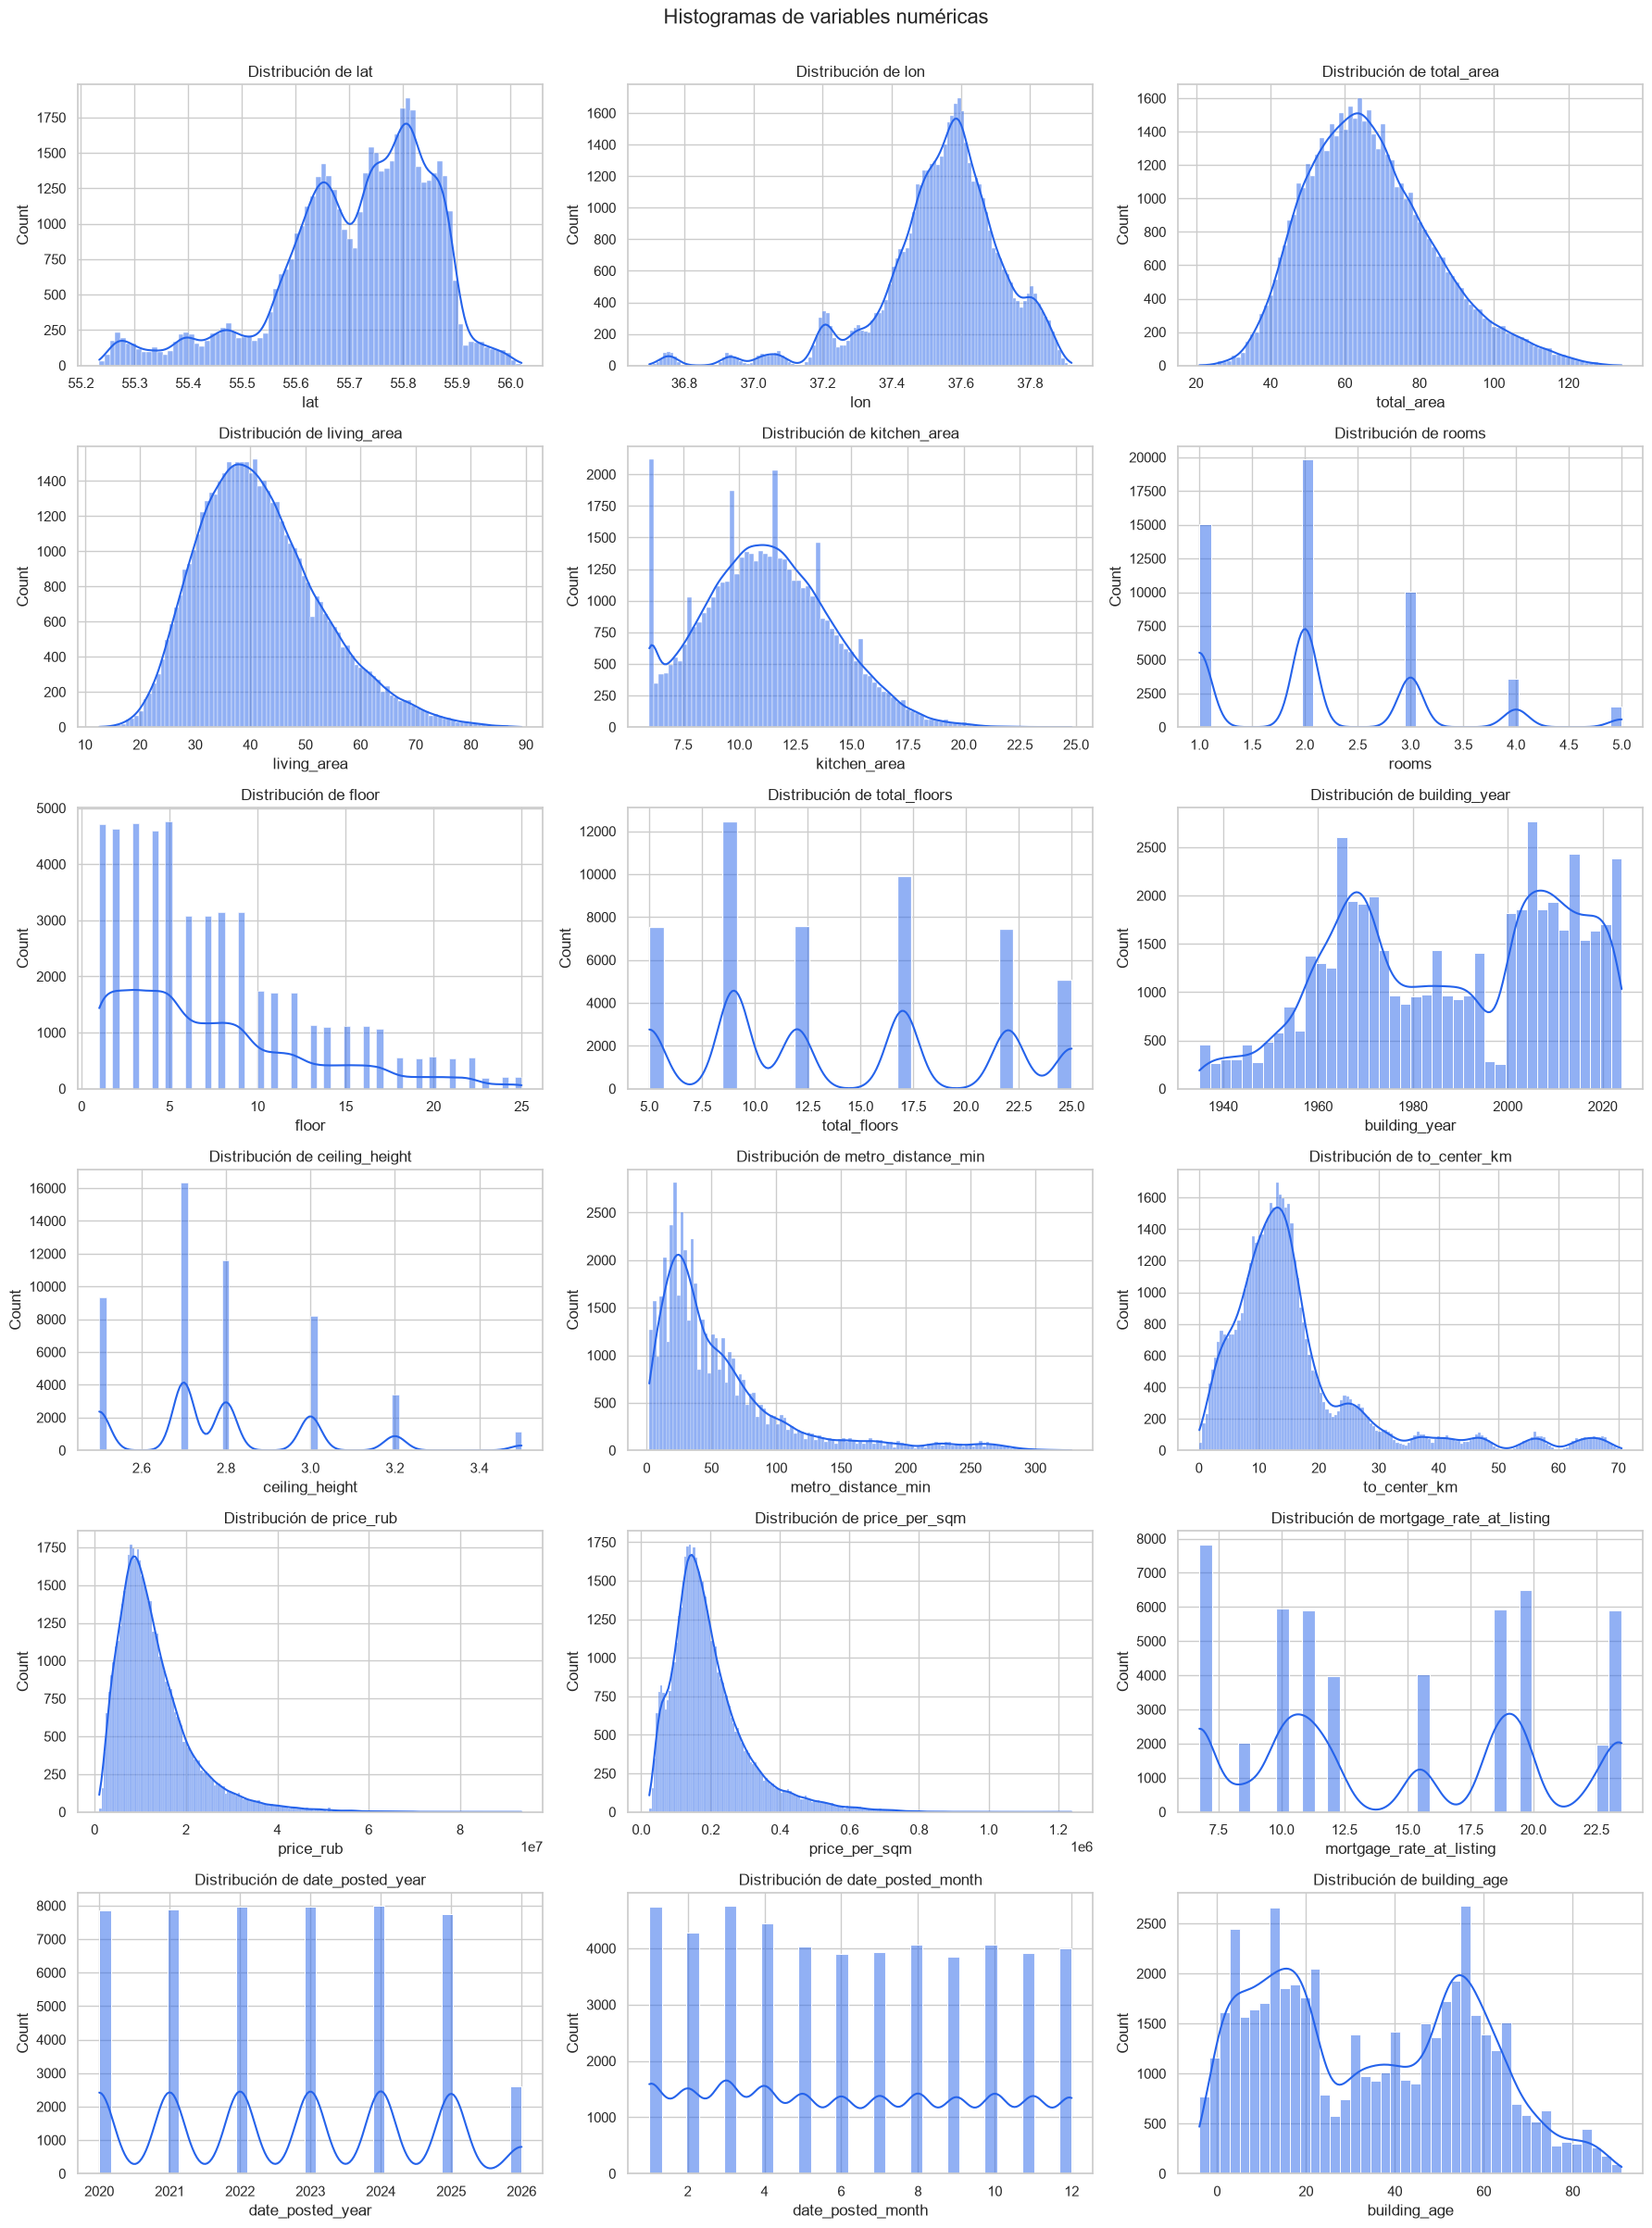

In [7]:
# Graficamos histogramas de todas las variables numéricas.
n_columnas = 3
n_filas = int(np.ceil(len(columnas_numericas) / n_columnas))
figura, ejes = plt.subplots(n_filas, n_columnas, figsize=(18, 4 * n_filas))
ejes = np.atleast_1d(ejes).ravel()
for eje, variable in zip(ejes, columnas_numericas):
    sns.histplot(data=df, x=variable, kde=True, ax=eje, color="#2563eb")
    eje.set_title(f"Distribución de {variable}")
for eje in ejes[len(columnas_numericas):]:
    eje.set_visible(False)
figura.suptitle("Histogramas de variables numéricas", y=1.002, fontsize=16)
figura.tight_layout()
figura.savefig(RUTA_GRAFICOS / "histogramas_numericas.png", dpi=150, bbox_inches="tight")
display(figura)
plt.close(figura)

### Análisis de los histogramas

El objetivo tiene media **195.625,67 RUB/m²**, mediana **170.400,00 RUB/m²**, asimetría **1,687**, mínimo **23.400** y máximo **1.239.100**. La diferencia entre media y mediana confirma una distribución sesgada hacia valores altos. En la regresión esto importa porque los precios extremos pueden pesar mucho en MAE, RMSE y en los coeficientes. Las colas deben investigarse; no justifican por sí solas eliminar filas.

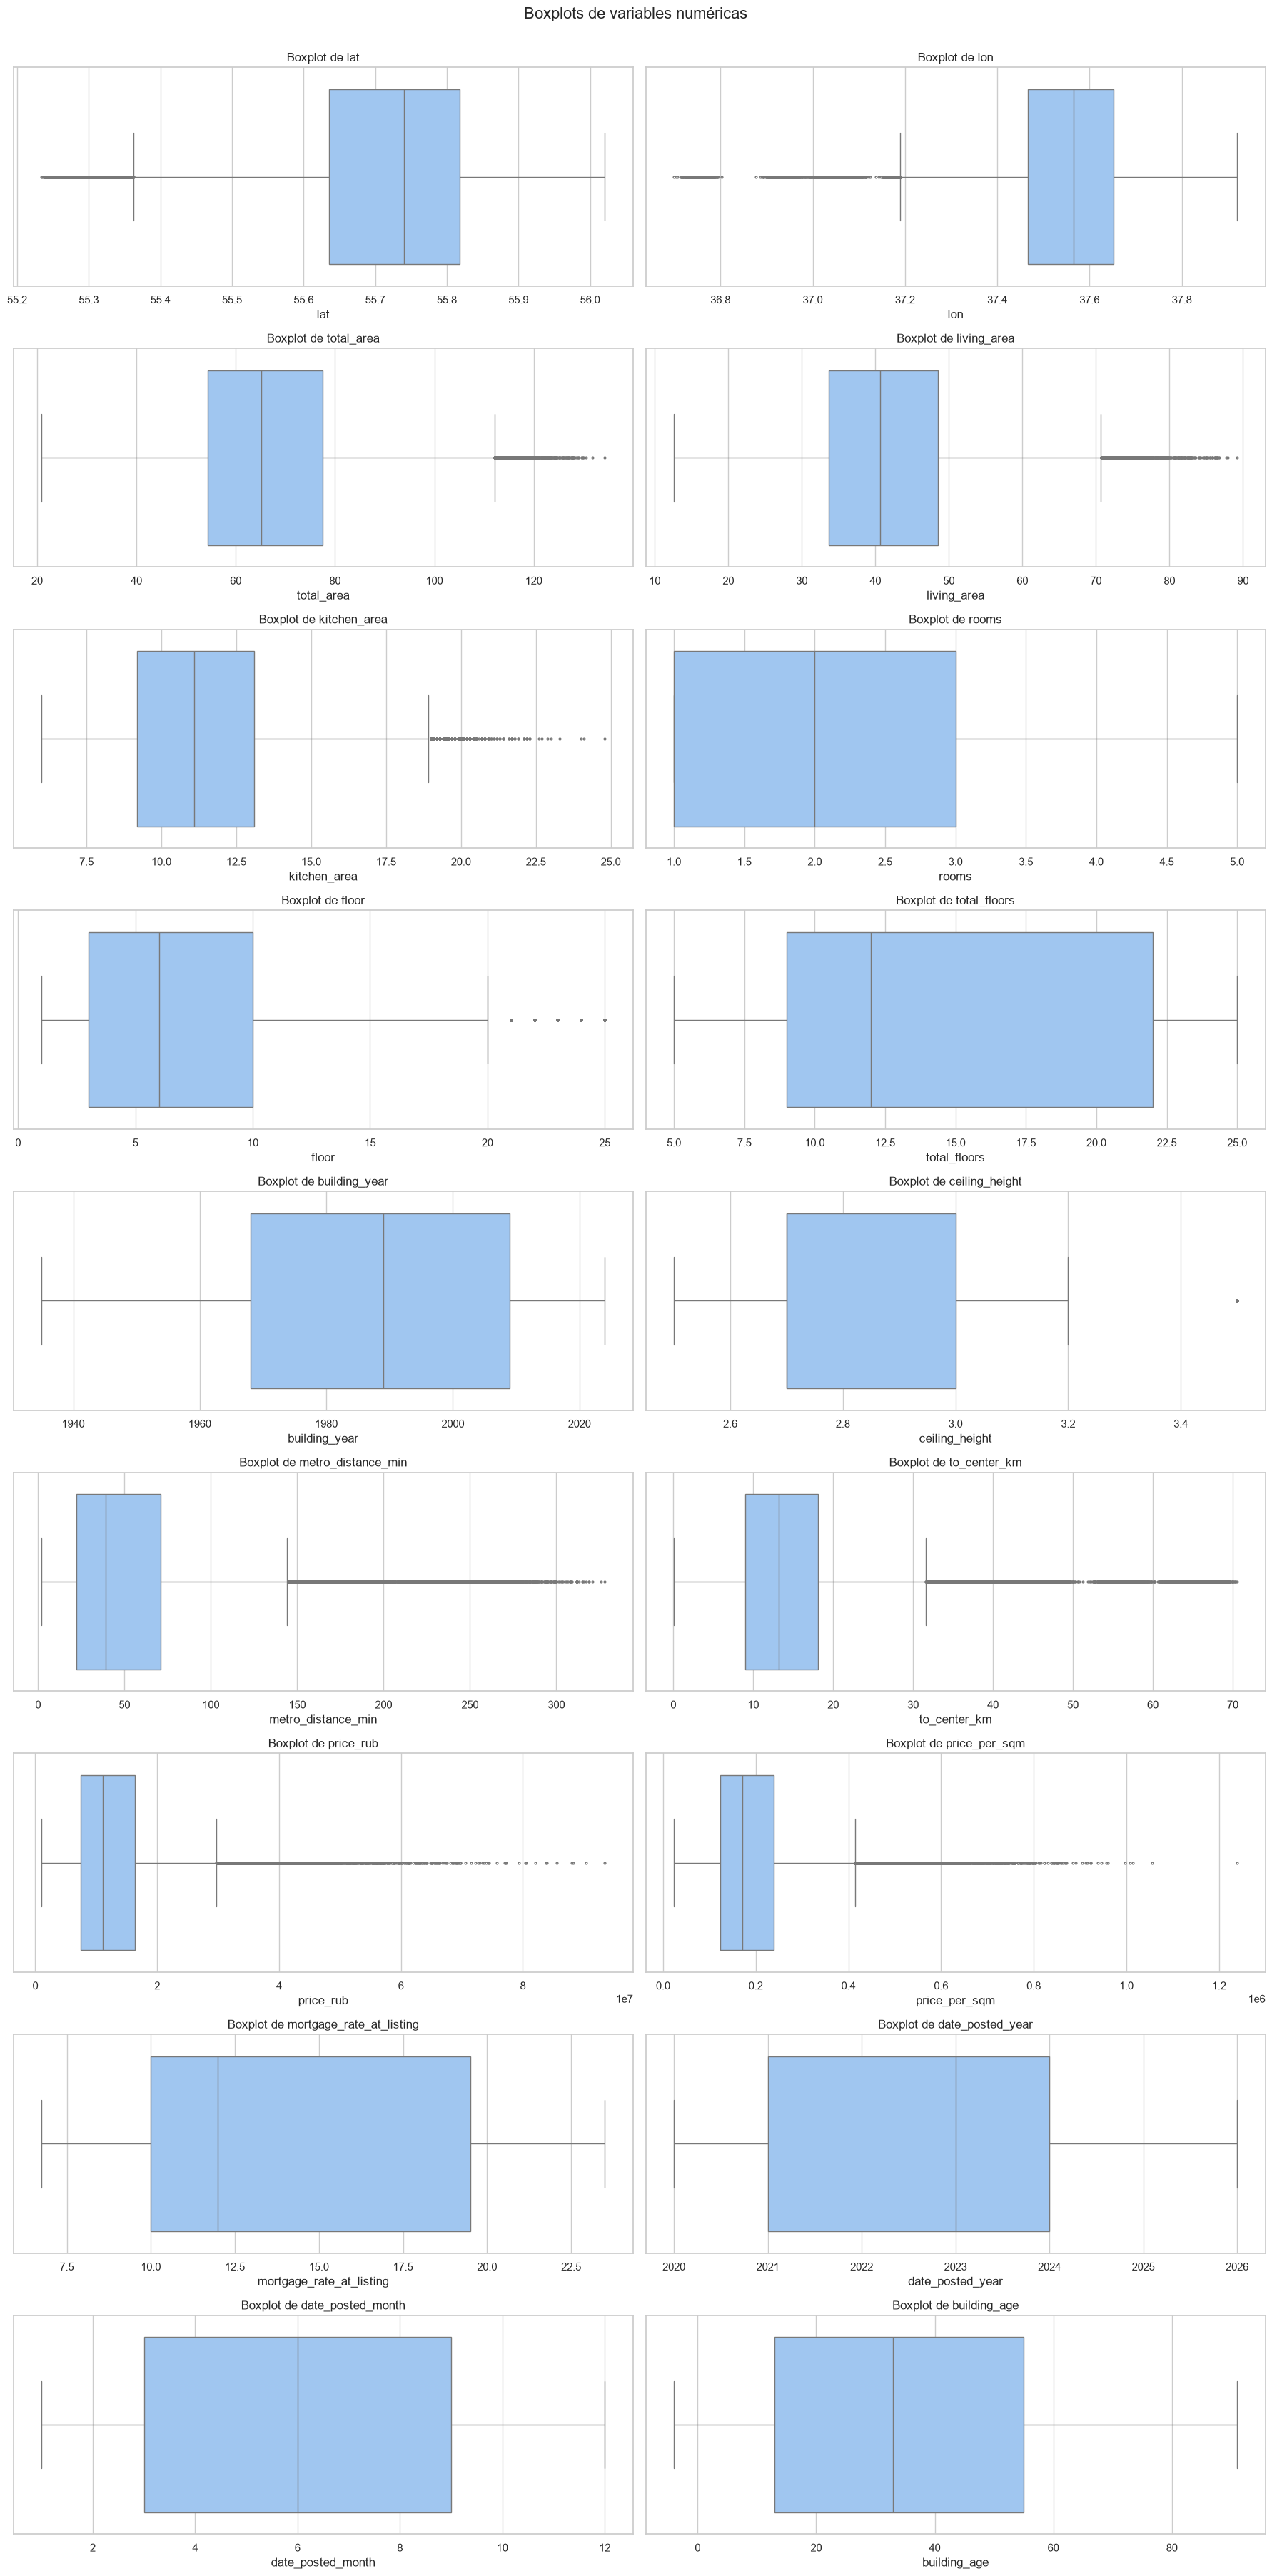

In [8]:
# Graficamos boxplots individuales para conservar una escala legible por variable.
n_columnas = 2
n_filas = int(np.ceil(len(columnas_numericas) / n_columnas))
figura, ejes = plt.subplots(n_filas, n_columnas, figsize=(18, 4 * n_filas))
ejes = np.atleast_1d(ejes).ravel()
for eje, variable in zip(ejes, columnas_numericas):
    sns.boxplot(data=df, x=variable, ax=eje, color="#93c5fd", fliersize=2)
    eje.set_title(f"Boxplot de {variable}")
for eje in ejes[len(columnas_numericas):]:
    eje.set_visible(False)
figura.suptitle("Boxplots de variables numéricas", y=1.002, fontsize=16)
figura.tight_layout()
figura.savefig(RUTA_GRAFICOS / "boxplots_numericas.png", dpi=150, bbox_inches="tight")
display(figura)
plt.close(figura)

### Análisis de los boxplots numéricos

Los boxplots permiten comparar escalas y localizar puntos alejados del rango central. En particular, `price_per_sqm` llega a **1.239.100 RUB/m²** y `building_age` toma como mínimo **-4**. Esto orienta la revisión de calidad y la interpretación del modelo, pero el gráfico no distingue automáticamente entre un error de carga y una propiedad real.

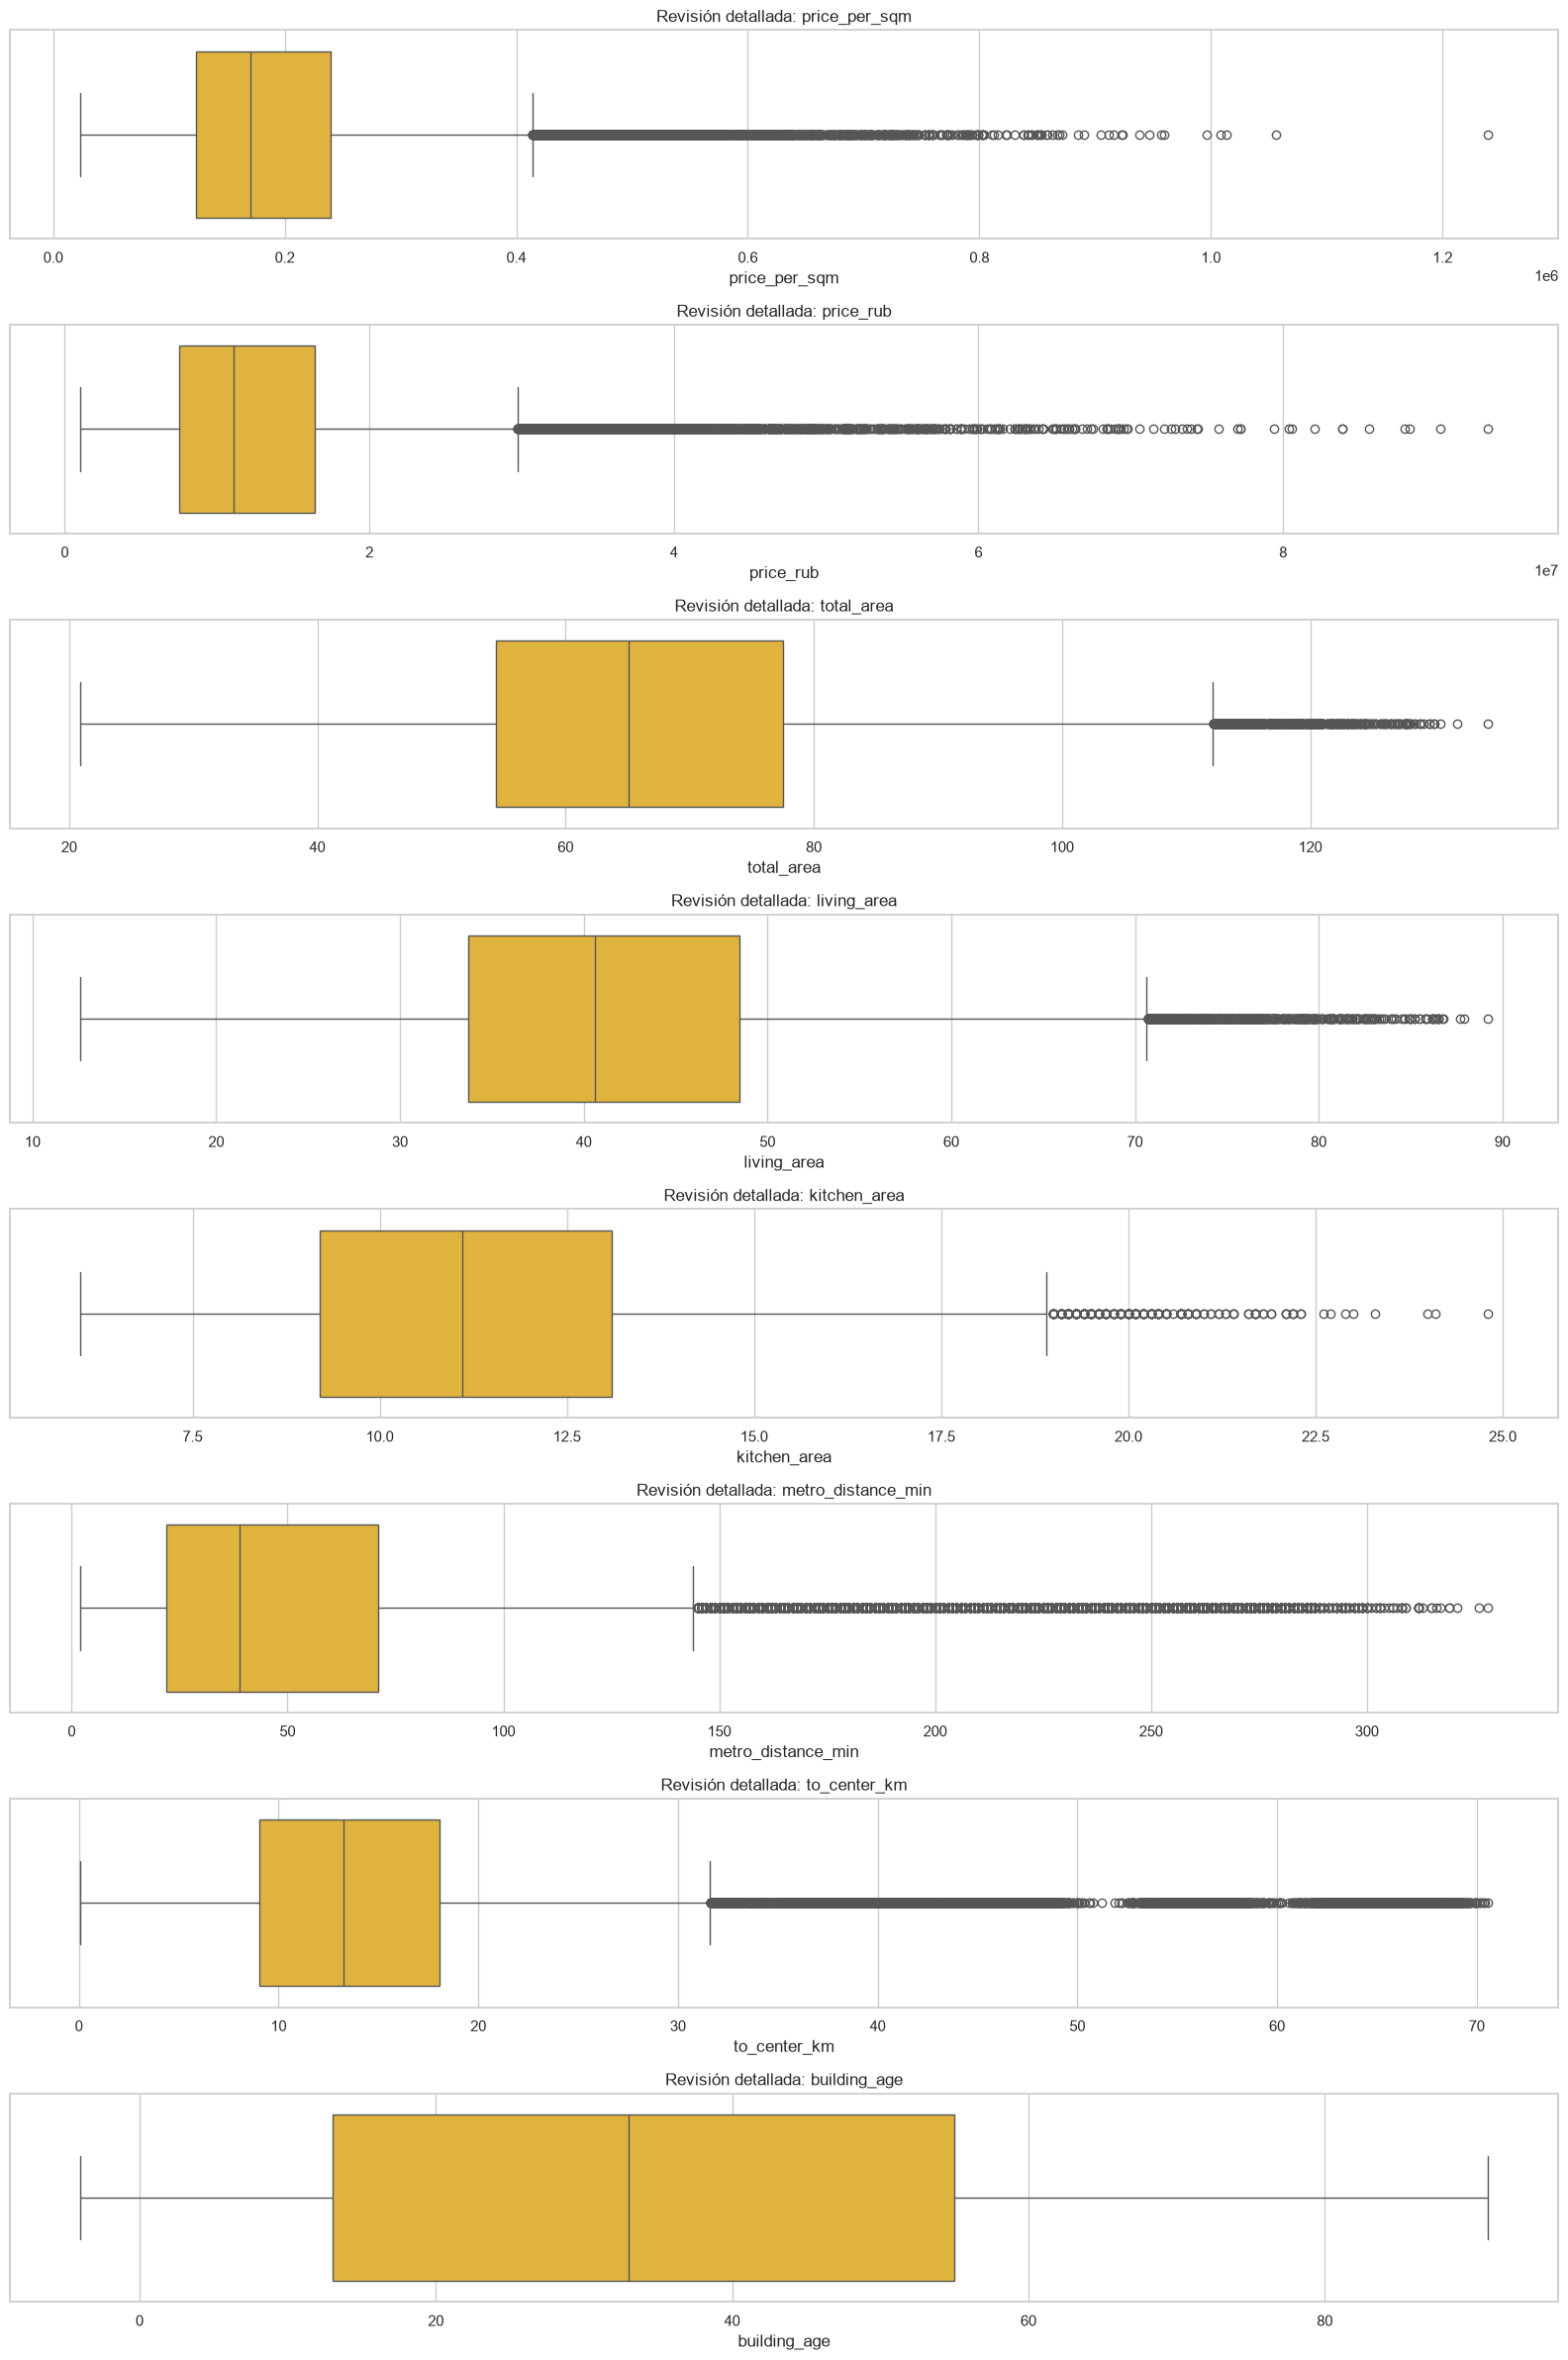

In [9]:
# Ampliamos la inspección del objetivo y de las variables numéricas más relevantes.
variables_sospechosas = [
    "price_per_sqm", "price_rub", "total_area", "living_area",
    "kitchen_area", "metro_distance_min", "to_center_km", "building_age"
]
figura, ejes = plt.subplots(len(variables_sospechosas), 1, figsize=(16, 3 * len(variables_sospechosas)))
for eje, variable in zip(ejes, variables_sospechosas):
    sns.boxplot(data=df, x=variable, ax=eje, color="#fbbf24")
    eje.set_title(f"Revisión detallada: {variable}")
figura.tight_layout()
figura.savefig(RUTA_GRAFICOS / "boxplots_variables_sospechosas.png", dpi=150, bbox_inches="tight")
display(figura)
plt.close(figura)

### Análisis de variables sospechosas

Este conjunto concentra las variables con mayor impacto potencial en el modelo: precio, superficies, distancia y antigüedad. `total_area`, `living_area` y `kitchen_area` deben leerse junto con sus unidades; `metro_distance_min` y `to_center_km` representan accesibilidad; `building_age` puede contener valores negativos por la relación entre año de construcción y fecha de publicación. La finalidad es decidir qué revisar y cómo describir el mercado, no aplicar un filtro automático.

## 3. Variables categóricas

Las frecuencias permiten saber si una categoría domina el dataset y si existen niveles con muy pocos registros. Para evitar gráficos ilegibles, mostramos todas las categorías en tablas y las principales categorías en los gráficos.

In [10]:
# Construimos tablas de frecuencia para cada variable categórica.
tablas_frecuencia = {}
for variable in columnas_categoricas:
    tabla = df[variable].value_counts(dropna=False).rename_axis(variable).reset_index(name="cantidad")
    tabla["porcentaje"] = tabla["cantidad"].div(len(df)).mul(100)
    tablas_frecuencia[variable] = tabla
    print(f"{variable}: {df[variable].nunique(dropna=False)} categorías")
    display(tabla.head(20))

id: 50000 categorías


,id,cantidad,porcentaje
0,S000001,1,0.002
1,S000002,1,0.002
2,S000003,1,0.002
3,S000004,1,0.002
4,S000005,1,0.002
5,S000006,1,0.002
6,S000007,1,0.002
7,S000008,1,0.002
8,S000009,1,0.002
9,S000010,1,0.002


district: 129 categorías


,district,cantidad,porcentaje
0,Begovoy,434,0.868
1,Yasenevo,430,0.860
2,Mikhaylovo-Yartsevskoye,427,0.854
3,Voronovskoye,422,0.844
4,Timiryazevsky,421,0.842
5,Orekhovo-Borisovo Yuzhnoye,419,0.838
6,Akademichesky,418,0.836
7,Lomonosovsky,416,0.832
8,Biryulyovo Vostochnoye,415,0.830
9,Tsaritsyno,415,0.830


okrug: 11 categorías


...

,metro_line,cantidad,porcentaje
0,Kaluzhsko-Rizhskaya,7165,14.330
1,Serpukhovsko-Timiryazevskaya,6745,13.490
2,Sokolnicheskaya,6408,12.816
3,Arbatsko-Pokrovskaya,5770,11.540
4,Zamoskvoretskaya,5014,10.028
5,Koltsevaya,4169,8.338
6,Filyovskaya,4081,8.162
7,Tagansko-Krasnopresnenskaya,3423,6.846
8,Lyublinsko-Dmitrovskaya,3006,6.012
9,Kalininskaya,2375,4.750


metro_distance_type: 2 categorías


,metro_distance_type,cantidad,porcentaje
0,transport,39771,79.542
1,walk,10229,20.458


seller_type: 2 categorías


,seller_type,cantidad,porcentaje
0,agency,32701,65.402
1,owner,17299,34.598


### Análisis de las frecuencias

Las categorías más frecuentes son `SVAO` en `okrug` (**6.662 filas**), `panel` en `building_type` (**10.143**), `cosmetic` en `renovation` (**20.057**), `agency` en `seller_type` (**32.701**), `transport` en `metro_distance_type` (**39.771**) y `True` en `has_balcony` (**37.490**). Esto muestra que la composición no es uniforme: una categoría muy rara puede generar un coeficiente OLS con gran incertidumbre y una dominante puede hacer que las comparaciones sean poco equilibradas.

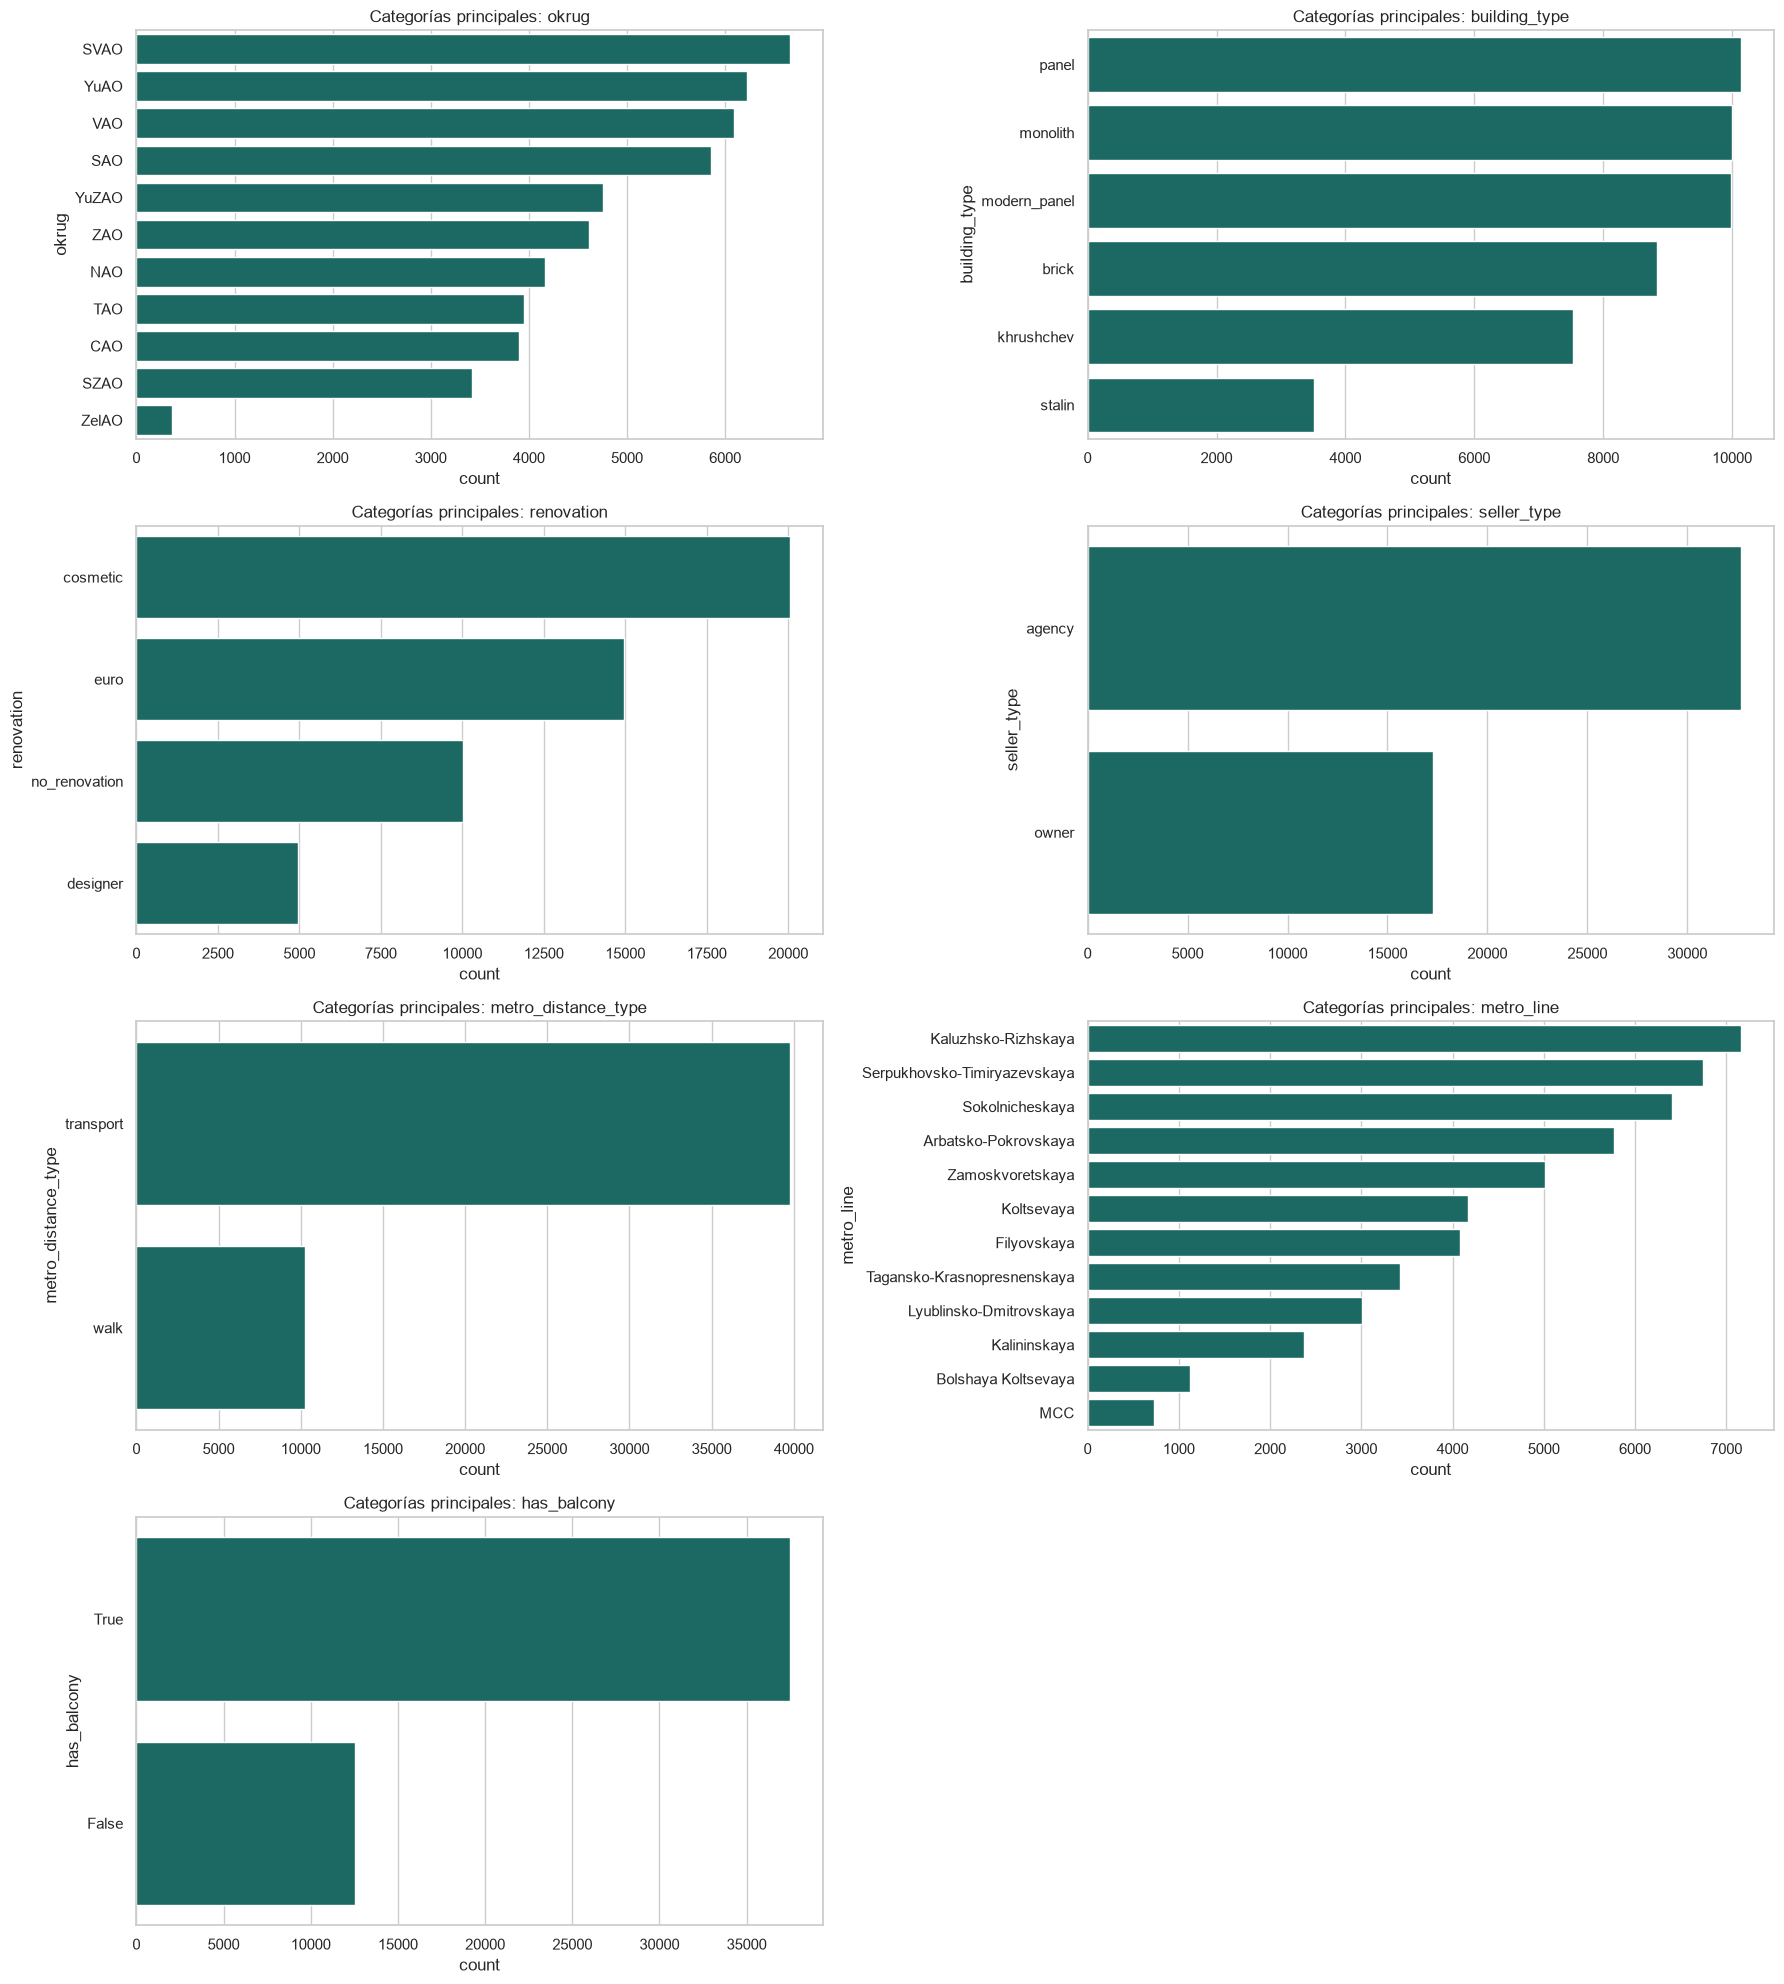

In [11]:
# Graficamos las categorías más frecuentes de las variables categóricas.
categoricas_para_graficar = [
    "okrug", "building_type", "renovation", "seller_type",
    "metro_distance_type", "metro_line", "has_balcony"
]
n_columnas = 2
n_filas = int(np.ceil(len(categoricas_para_graficar) / n_columnas))
figura, ejes = plt.subplots(n_filas, n_columnas, figsize=(18, 5 * n_filas))
ejes = np.atleast_1d(ejes).ravel()
for eje, variable in zip(ejes, categoricas_para_graficar):
    orden = df[variable].value_counts().head(15).index
    sns.countplot(data=df, y=variable, order=orden, ax=eje, color="#0f766e")
    eje.set_title(f"Categorías principales: {variable}")
for eje in ejes[len(categoricas_para_graficar):]:
    eje.set_visible(False)
figura.tight_layout()
figura.savefig(RUTA_GRAFICOS / "countplots_categoricas.png", dpi=150, bbox_inches="tight")
display(figura)
plt.close(figura)

### Análisis de los countplots

Los gráficos confirman el desbalance observado en las tablas: `agency` concentra aproximadamente dos tercios de las publicaciones y `transport` es mucho más frecuente que `walk`. Esto afecta la lectura del stakeholder porque una mediana de un grupo pequeño puede ser inestable. Estos gráficos describen composición del dataset, no prueban que una categoría cause un precio mayor.

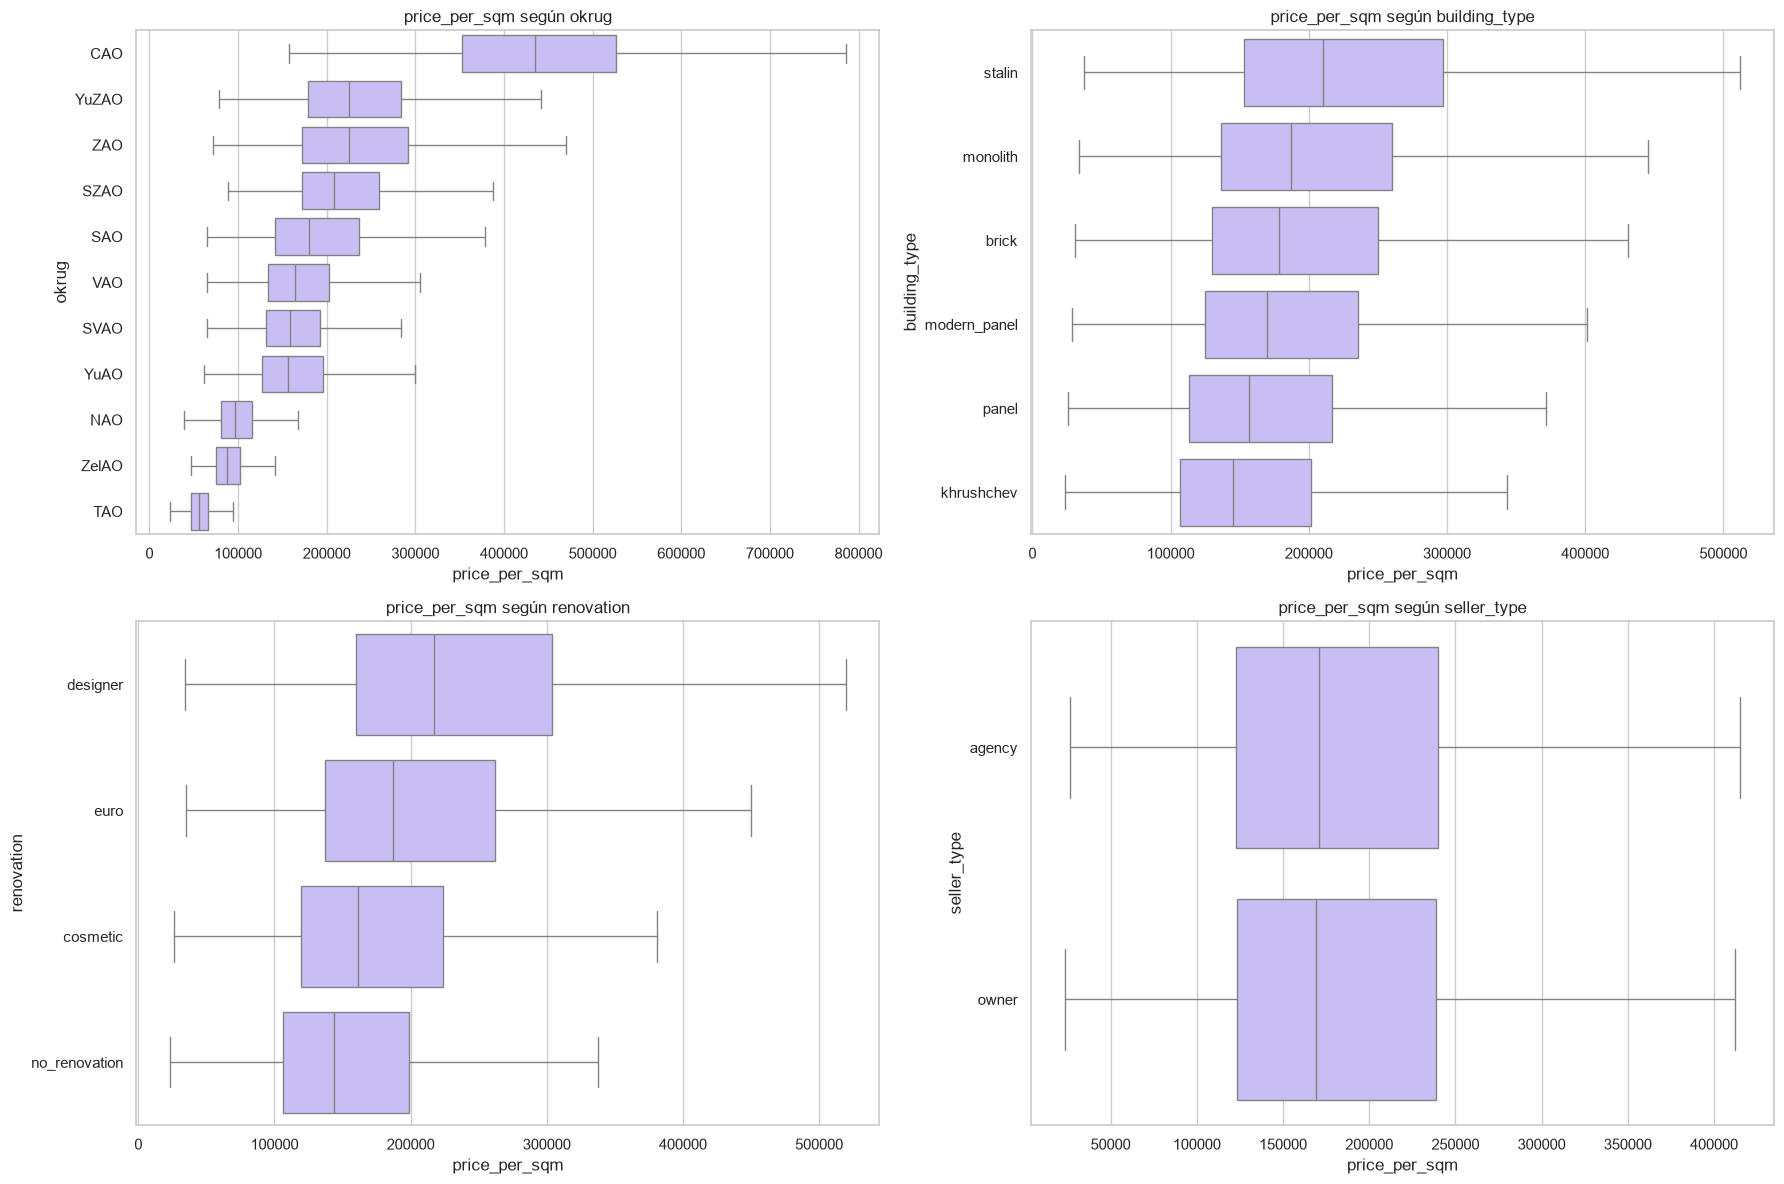

In [12]:
# Comparamos la distribución del objetivo entre categorías relevantes.
categorias_objetivo = ["okrug", "building_type", "renovation", "seller_type"]
n_columnas = 2
n_filas = int(np.ceil(len(categorias_objetivo) / n_columnas))
figura, ejes = plt.subplots(n_filas, n_columnas, figsize=(18, 6 * n_filas))
ejes = np.atleast_1d(ejes).ravel()
for eje, variable in zip(ejes, categorias_objetivo):
    orden = df.groupby(variable)["price_per_sqm"].median().sort_values(ascending=False).head(15).index
    sns.boxplot(data=df[df[variable].isin(orden)], y=variable, x="price_per_sqm", order=orden, ax=eje, color="#c4b5fd", showfliers=False)
    eje.set_title(f"price_per_sqm según {variable}")
for eje in ejes[len(categorias_objetivo):]:
    eje.set_visible(False)
figura.tight_layout()
figura.savefig(RUTA_GRAFICOS / "objetivo_por_categoria.png", dpi=150, bbox_inches="tight")
display(figura)
plt.close(figura)

### Análisis del objetivo por categoría

La mediana de `price_per_sqm` cambia entre categorías. En `okrug`, el grupo con menor mediana es **TAO (55.800,00 RUB/m²)** y el mayor es **CAO (434.500,00 RUB/m²)**. En `building_type`, el rango va de **145.300,00** a **210.600,00 RUB/m²**. La separación entre cajas indica capacidad descriptiva, pero en OLS cada efecto se interpreta respecto de una categoría de referencia y manteniendo constantes las demás variables.

## 4. Relaciones numéricas y correlación

La correlación ayuda a explorar relaciones lineales, pero no demuestra causalidad. También debemos revisar correlaciones altas entre predictores, porque pueden volver inestable la interpretación de los coeficientes.

,correlacion_con_objetivo
price_per_sqm,1.000
price_rub,0.889
lat,0.299
lon,0.253
date_posted_year,0.192
mortgage_rate_at_listing,0.167
ceiling_height,0.077
building_year,0.021
date_posted_month,0.015
floor,0.014


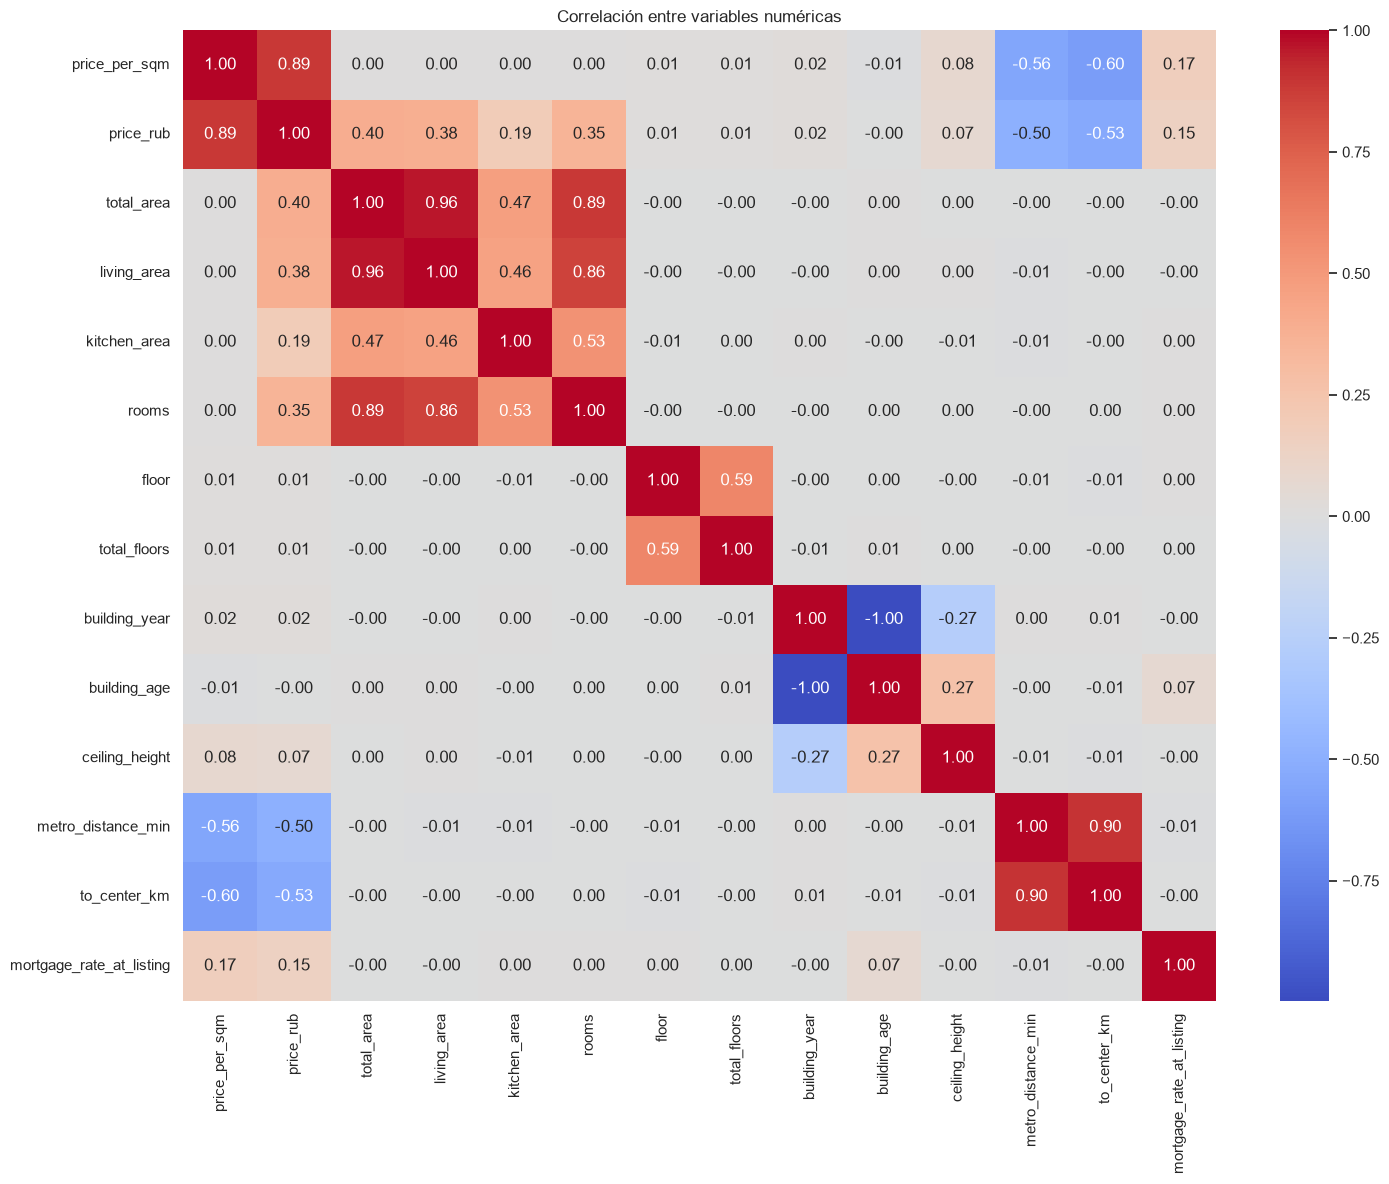

In [13]:
# Calculamos la matriz de correlación de las variables numéricas originales.
matriz_correlacion = df[columnas_numericas].corr(numeric_only=True)
correlaciones_objetivo = matriz_correlacion["price_per_sqm"].sort_values(ascending=False).to_frame("correlacion_con_objetivo")
display(correlaciones_objetivo)

# Mostramos un heatmap legible con las variables numéricas principales.
variables_heatmap = [
    "price_per_sqm", "price_rub", "total_area", "living_area",
    "kitchen_area", "rooms", "floor", "total_floors",
    "building_year", "building_age", "ceiling_height",
    "metro_distance_min", "to_center_km", "mortgage_rate_at_listing"
]
figura, eje = plt.subplots(figsize=(15, 12))
sns.heatmap(df[variables_heatmap].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=eje)
eje.set_title("Correlación entre variables numéricas")
figura.tight_layout()
figura.savefig(RUTA_GRAFICOS / "heatmap_correlacion.png", dpi=150, bbox_inches="tight")
display(figura)
plt.close(figura)

### Análisis del heatmap

La correlación numérica más alta con `price_per_sqm` es **price_rub (0,889)**, pero no es una señal utilizable porque `price_rub` está derivado del precio por m². Entre variables utilizables, las relaciones más fuertes son `to_center_km` (**-0,600**) y `metro_distance_min` (**-0,557**). Esto sirve para priorizar relaciones lineales, pero no decide por sí solo qué variable queda en el modelo. También hay que mirar celdas altas entre predictores: indican posible redundancia y dificultan atribuir un efecto individual a cada coeficiente.

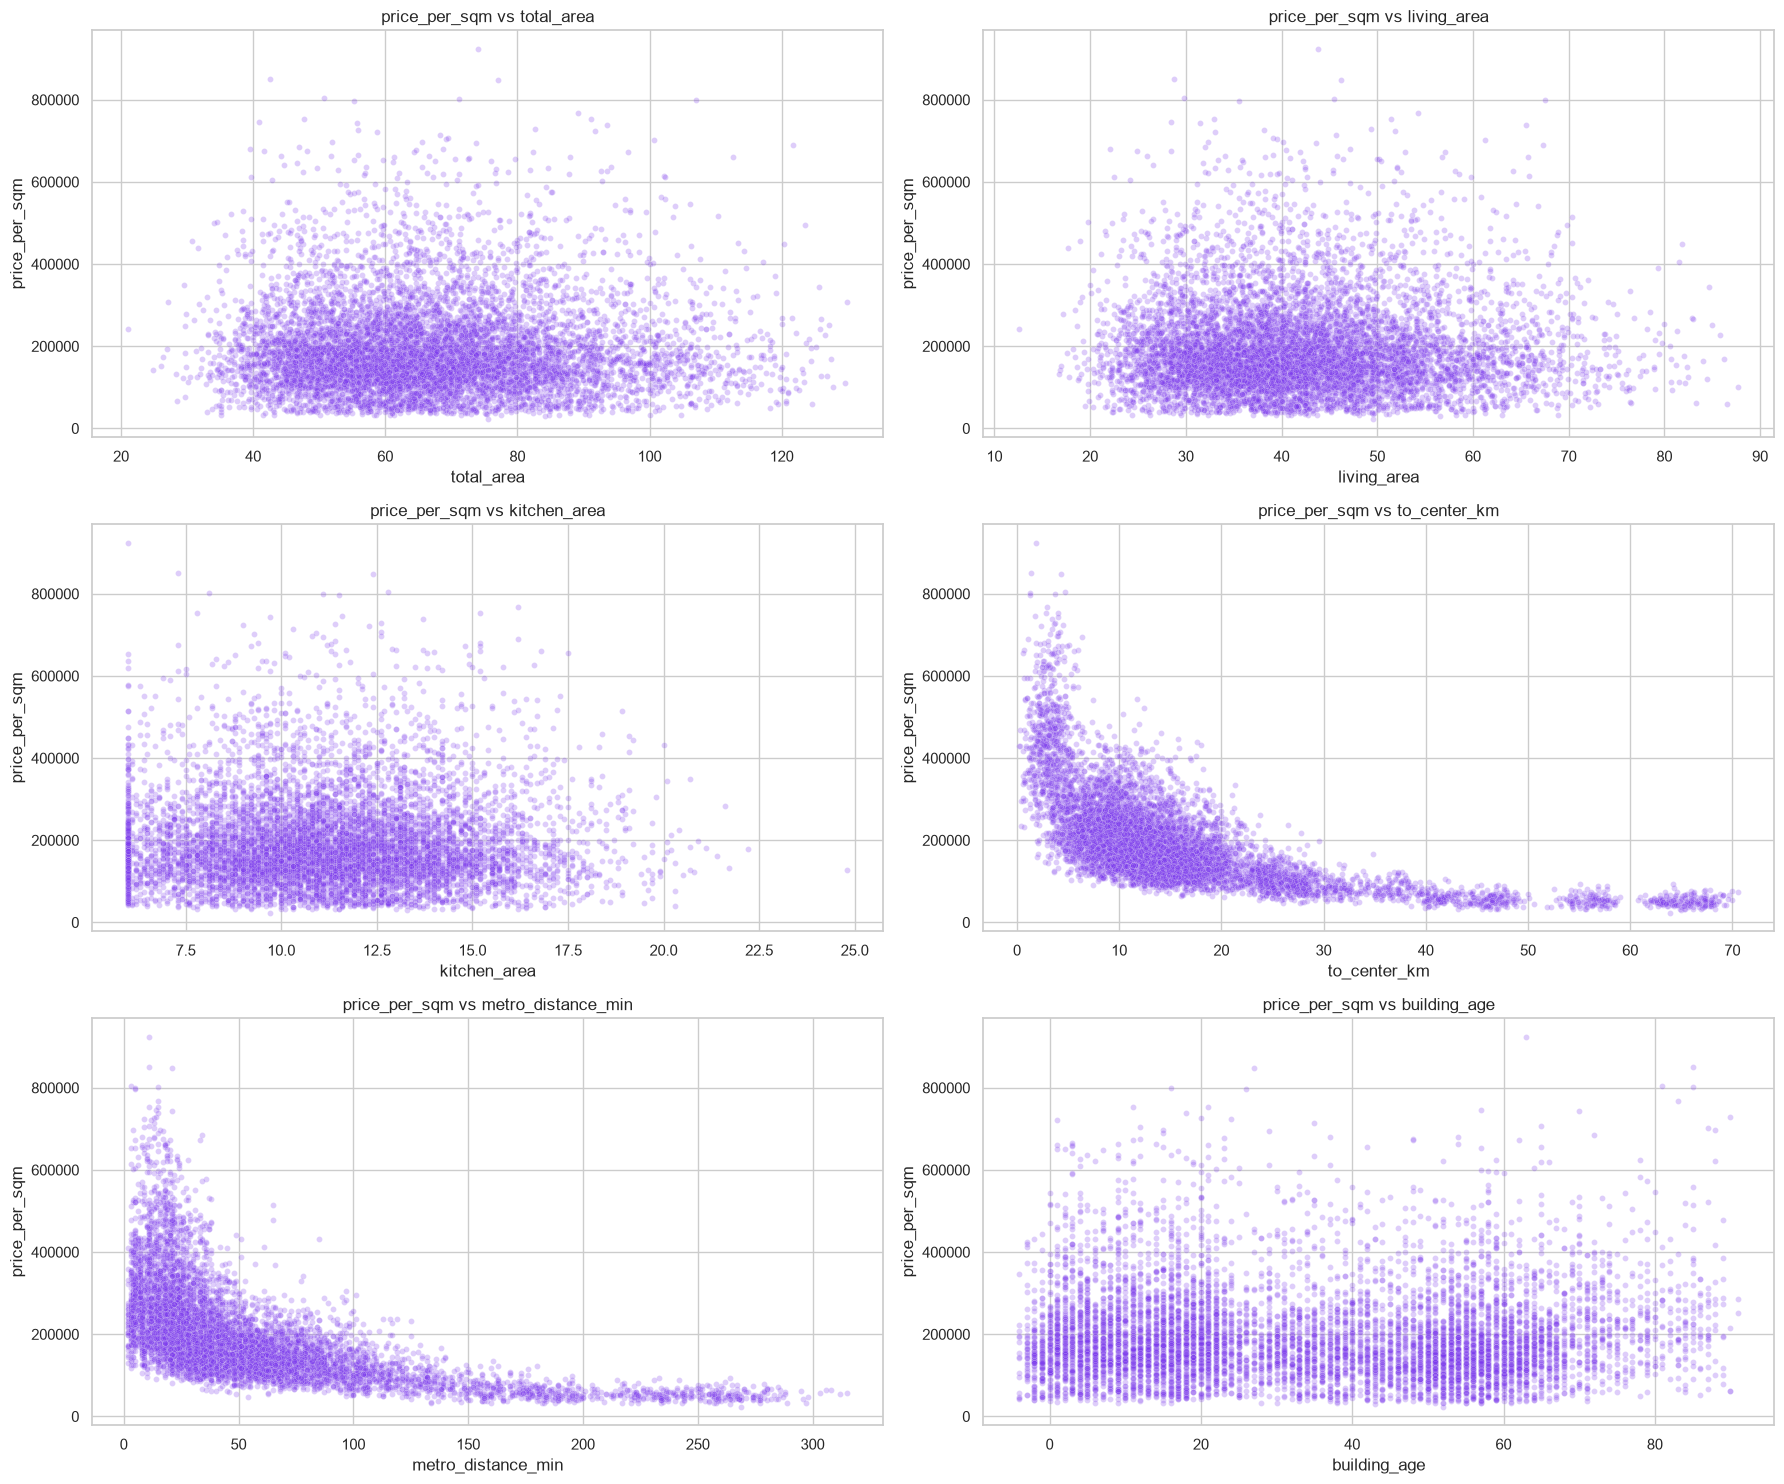

In [14]:
# Graficamos relaciones directas entre el objetivo y variables numéricas interpretables.
variables_scatter = ["total_area", "living_area", "kitchen_area", "to_center_km", "metro_distance_min", "building_age"]
muestra_scatter = df.sample(n=min(8000, len(df)), random_state=42)
n_columnas = 2
n_filas = int(np.ceil(len(variables_scatter) / n_columnas))
figura, ejes = plt.subplots(n_filas, n_columnas, figsize=(18, 5 * n_filas))
ejes = np.atleast_1d(ejes).ravel()
for eje, variable in zip(ejes, variables_scatter):
    sns.scatterplot(data=muestra_scatter, x=variable, y="price_per_sqm", alpha=0.25, s=18, ax=eje, color="#7c3aed")
    eje.set_title(f"price_per_sqm vs {variable}")
for eje in ejes[len(variables_scatter):]:
    eje.set_visible(False)
figura.tight_layout()
figura.savefig(RUTA_GRAFICOS / "scatter_objetivo_numericas.png", dpi=150, bbox_inches="tight")
display(figura)
plt.close(figura)

### Análisis de los scatterplots

Los scatterplots muestran si las correlaciones anteriores tienen una forma aproximadamente lineal o si están dominadas por grupos y extremos. Para el objetivo, `total_area` tiene correlación **0.003**, `to_center_km` **-0.600** y `metro_distance_min` **-0.557**. La amplitud vertical de la nube indica que una sola variable no explica todo el precio; por eso se comparan varias características en el OLS.

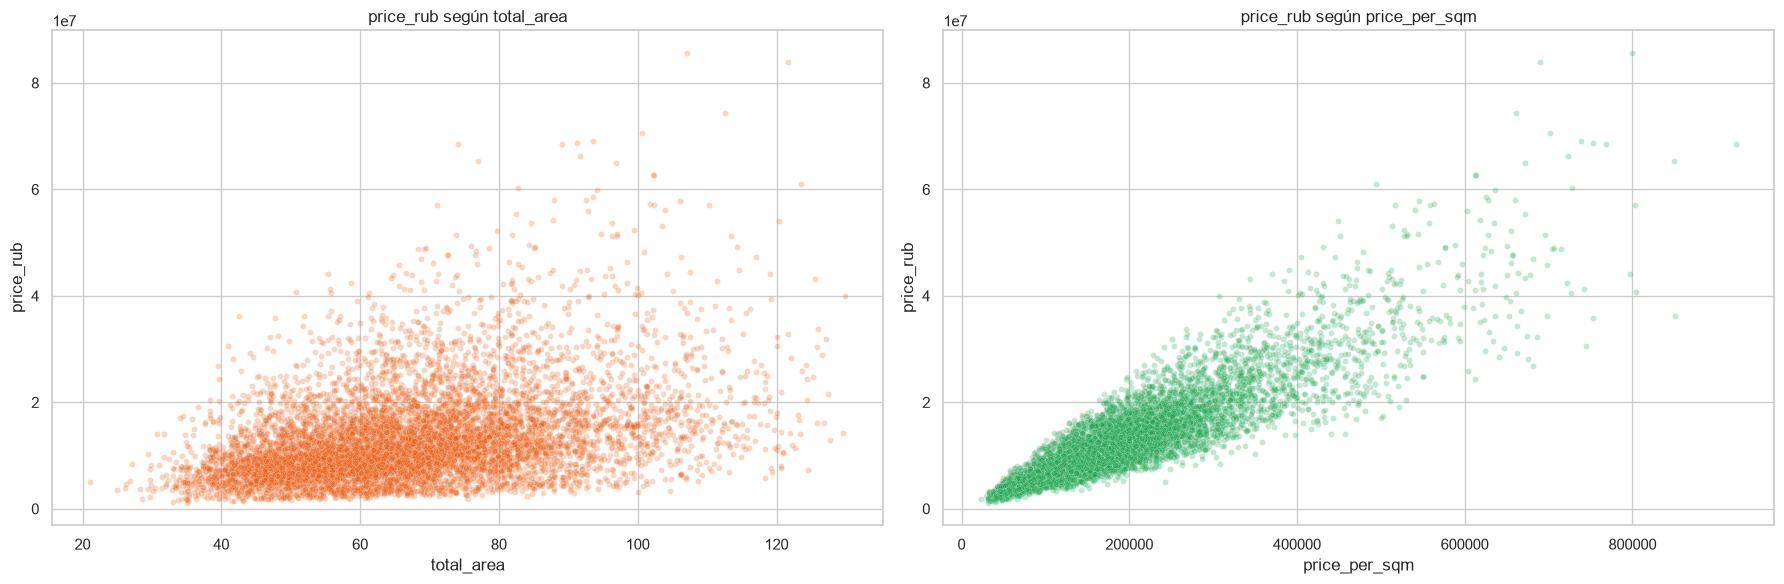

In [15]:
# price_rub y total_area ayudan a revisar la relación aritmética del dataset.
figura, ejes = plt.subplots(1, 2, figsize=(18, 6))
sns.scatterplot(data=muestra_scatter, x="total_area", y="price_rub", alpha=0.25, s=18, ax=ejes[0], color="#ea580c")
ejes[0].set_title("price_rub según total_area")
sns.scatterplot(data=muestra_scatter, x="price_per_sqm", y="price_rub", alpha=0.25, s=18, ax=ejes[1], color="#16a34a")
ejes[1].set_title("price_rub según price_per_sqm")
figura.tight_layout()
figura.savefig(RUTA_GRAFICOS / "relaciones_precio_superficie.png", dpi=150, bbox_inches="tight")
display(figura)
plt.close(figura)

### Análisis de precio total y superficie

`price_rub` está conceptualmente ligado a superficie y precio por m². Por eso aparece aquí como control descriptivo. La discrepancia mayor a 1 RUB en **49.814 filas** demuestra que no conviene entregarle `price_rub` al modelo para explicar `price_per_sqm`: puede introducir información derivada del objetivo. Para el baseline se conserva como variable excluida, no como predictor.

## 5. Tiempo y ubicación

La fecha de publicación es importante porque el mercado puede cambiar con el tiempo. Las coordenadas permiten observar la cobertura espacial del dataset sin convertir todavía la ubicación en una decisión de modelado.

,periodo,publicaciones,mediana_price_per_sqm,media_price_per_sqm
0,2020-01,678,"120,300.000","139,370.059"
1,2020-02,645,"124,100.000","142,880.465"
2,2020-03,690,"127,850.000","145,625.507"
3,2020-04,640,"134,700.000","148,769.688"
4,2020-05,637,"127,100.000","148,919.466"
5,2020-06,657,"132,500.000","152,035.616"
6,2020-07,685,"133,200.000","153,549.489"
7,2020-08,653,"130,500.000","152,169.219"
8,2020-09,622,"140,800.000","161,154.823"
9,2020-10,648,"137,050.000","155,194.753"


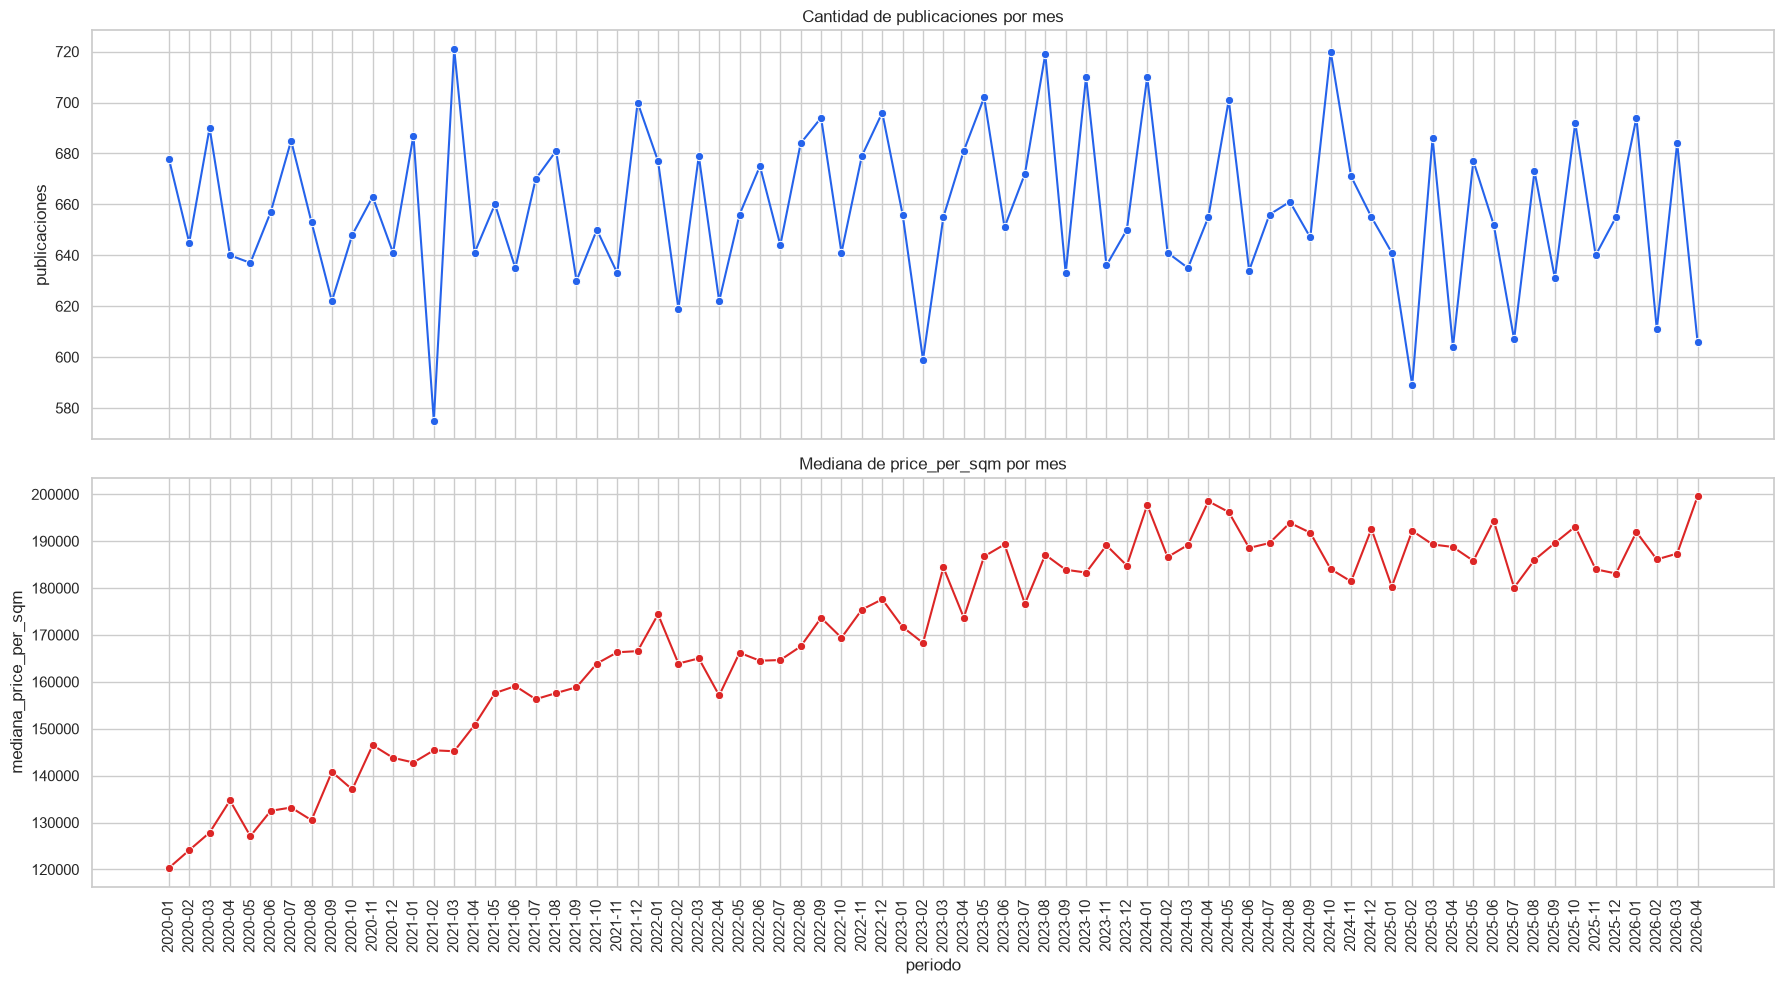

In [16]:
# Resumimos cantidad de publicaciones y mediana del objetivo por mes.
df["periodo"] = df["date_posted"].dt.to_period("M").astype(str)
resumen_temporal = df.groupby("periodo").agg(
    publicaciones=("id", "count"),
    mediana_price_per_sqm=("price_per_sqm", "median"),
    media_price_per_sqm=("price_per_sqm", "mean")
).reset_index()
display(resumen_temporal)

figura, ejes = plt.subplots(2, 1, figsize=(18, 10), sharex=True)
sns.lineplot(data=resumen_temporal, x="periodo", y="publicaciones", marker="o", ax=ejes[0], color="#2563eb")
sns.lineplot(data=resumen_temporal, x="periodo", y="mediana_price_per_sqm", marker="o", ax=ejes[1], color="#dc2626")
ejes[0].set_title("Cantidad de publicaciones por mes")
ejes[1].set_title("Mediana de price_per_sqm por mes")
ejes[1].tick_params(axis="x", rotation=90)
figura.tight_layout()
figura.savefig(RUTA_GRAFICOS / "evolucion_temporal.png", dpi=150, bbox_inches="tight")
display(figura)
plt.close(figura)

### Análisis temporal

Las publicaciones cubren desde **2020-01-01** hasta **2026-04-29**. La mediana mensual de `price_per_sqm` va aproximadamente de **120.300,00** a **199.550,00 RUB/m²**. Si el nivel del objetivo cambia con el tiempo, una división aleatoria puede mezclar pasado y futuro y dar una evaluación demasiado optimista. Por eso el baseline final usa un corte temporal.

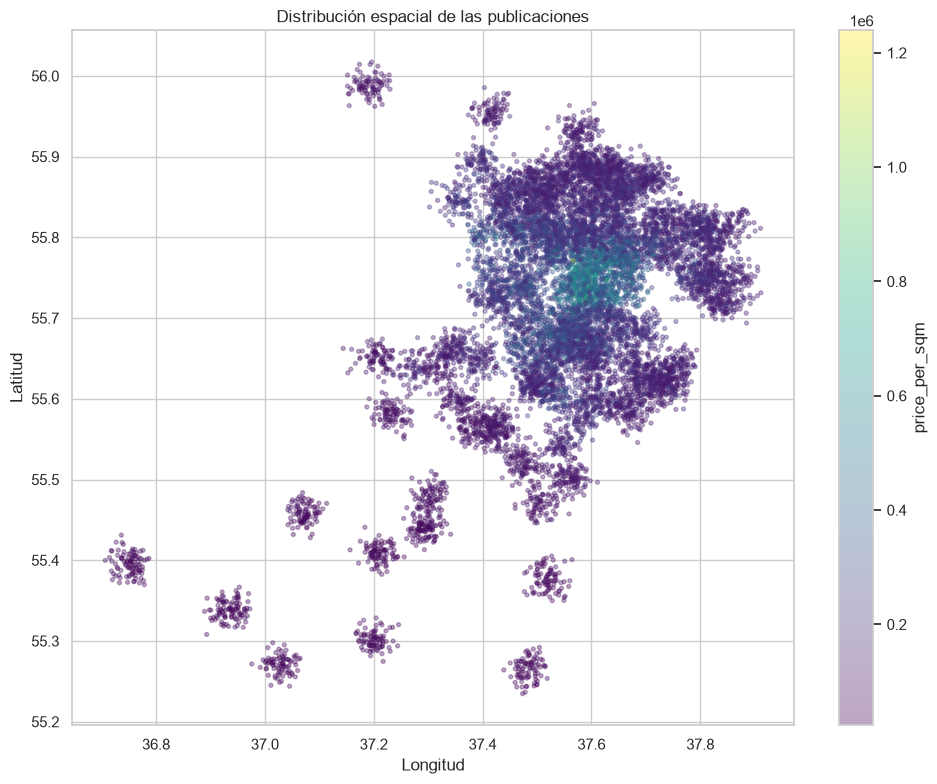

In [17]:
# Visualizamos la cobertura geográfica coloreando por precio por metro cuadrado.
muestra_mapa = df.sample(n=min(12000, len(df)), random_state=42)
figura, eje = plt.subplots(figsize=(10, 8))
grafico = eje.scatter(muestra_mapa["lon"], muestra_mapa["lat"], c=muestra_mapa["price_per_sqm"], s=8, alpha=0.35, cmap="viridis")
figura.colorbar(grafico, ax=eje, label="price_per_sqm")
eje.set(title="Distribución espacial de las publicaciones", xlabel="Longitud", ylabel="Latitud")
figura.tight_layout()
figura.savefig(RUTA_GRAFICOS / "mapa_publicaciones_precio.png", dpi=150, bbox_inches="tight")
display(figura)
plt.close(figura)

### Análisis espacial

El mapa cubre latitudes de **55.234 a 56.020** y longitudes de **36.699 a 37.920**. El color representa `price_per_sqm`; concentraciones de colores similares pueden indicar diferencias geográficas. En el modelo esas diferencias pueden representarse con `district`, estaciones o coordenadas, pero el mapa no demuestra por sí mismo un efecto causal.

## 6. Preparación de variables para modelado exploratorio

Esta sección muestra cómo pasar de las variables descriptivas a una matriz numérica. No reemplaza el corte temporal del notebook baseline: el modelo que aparece aquí es exploratorio y usa una división aleatoria 80/20 para ilustrar el flujo solicitado.

Se excluyen `id`, `date_posted` y `price_rub`. También se excluyen `periodo`, `building_year`, `okrug` y `metro_line`: `periodo` es una columna auxiliar del EDA, `building_year` es redundante con `building_age`, y `okrug`/`metro_line` son niveles jerárquicos de `district`/`metro_station`. Así evitamos introducir dependencias exactas en la matriz de diseño.

In [18]:
# Excluimos identificadores, variables derivadas o redundantes y el precio total.
columnas_excluir_modelo_eda = [
    "id", "date_posted", "price_rub", "periodo",
    "building_year", "okrug", "metro_line"
]
df_para_modelar = df.drop(columns=columnas_excluir_modelo_eda).copy()
y_eda = df_para_modelar.pop("price_per_sqm")
X_eda = pd.get_dummies(df_para_modelar, drop_first=True, dtype=float)

print(f"Columnas excluidas: {columnas_excluir_modelo_eda}")
print(f"Matriz X antes de separar: {X_eda.shape[0]:,} filas x {X_eda.shape[1]:,} predictores")
print(f"Objetivo: {y_eda.name}")
print(f"price_rub en X: {'price_rub' in X_eda.columns}")
print(f"Valores faltantes en X: {int(X_eda.isna().sum().sum()):,}")
display(X_eda.head())

Columnas excluidas: ['id', 'date_posted', 'price_rub', 'periodo', 'building_year', 'okrug', 'metro_line']
Matriz X antes de separar: 50,000 filas x 257 predictores
Objetivo: price_per_sqm
price_rub en X: False
Valores faltantes en X: 0


,lat,lon,total_area,living_area,kitchen_area,rooms,floor,total_floors,ceiling_height,has_balcony,metro_distance_min,to_center_km,mortgage_rate_at_listing,date_posted_year,date_posted_month,building_age,district_Akademichesky,district_Alekseevsky,district_Altufyevsky,district_Arbat,district_Babushkinsky,district_Basmanny,district_Begovoy,district_Beskudnikovsky,district_Bibirevo,district_Biryulyovo Vostochnoye,district_Biryulyovo Zapadnoye,district_Bogorodskoye,district_Brateyevo,district_Butyrsky,district_Chertanovo Severnoye,district_Chertanovo Tsentralnoye,district_Chertanovo Yuzhnoye,district_Cheryomushki,district_Danilovsky,district_Desyonovskoye,district_Dmitrovsky,district_Donskoy,district_Dorogomilovo,district_Fili-Davydkovo,district_Filimonkovskoye,district_Filyovsky Park,district_Gagarinsky,district_Golovinsky,district_Golyanovo,district_Ivanovskoye,district_Izmaylovo,district_Khamovniki,district_Khoroshyovo-Mnyovniki,district_Khoroshyovsky,...,metro_station_Prospekt Vernadskogo,metro_station_Pushkinskaya,metro_station_Pyatnitskoye Shosse,metro_station_Rechnoy Vokzal,metro_station_Rimskaya,metro_station_Rizhskaya,metro_station_Sapyornoye Pole,metro_station_Semyonovskaya,metro_station_Serpukhovskaya,metro_station_Sevastopolskaya,metro_station_Shabolovskaya,metro_station_Shchukinskaya,metro_station_Shchyolkovskaya,metro_station_Shosse Entuziastov,metro_station_Slavyansky Bulvar,metro_station_Smolenskaya (AP),metro_station_Smolenskaya (F),metro_station_Sokol,metro_station_Sokolniki,metro_station_Sportivnaya,metro_station_Sretensky Bulvar,metro_station_Strogino,metro_station_Studencheskaya,metro_station_Sukharevskaya,metro_station_Sviblovo,metro_station_Taganskaya,metro_station_Teatralnaya,metro_station_Tekstilshchiki,metro_station_Timiryazevskaya,metro_station_Tretyakovskaya,metro_station_Troparyovo,metro_station_Trubnaya,metro_station_Tsvetnoy Bulvar,metro_station_Tulskaya,metro_station_Turgenevskaya,metro_station_Tverskaya,metro_station_Tyoply Stan,metro_station_Ugreshskaya,metro_station_Ulitsa 1905 Goda,metro_station_Ulitsa Akademika Yangelya,metro_station_Ulitsa Podbelskogo,metro_station_Universitet,metro_station_VDNKh,metro_station_Voykovskaya,metro_station_Vystavochnaya,metro_station_Yasenevo,metro_station_Yugo-Zapadnaya,metro_station_Yuzhnaya,metro_distance_type_walk,seller_type_owner
0,55.795,37.555,71.000,46.500,6.100,2,19,25,2.500,True,18,6.170,23.500,2024,11,55,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
1,55.797,37.689,79.600,52.800,10.800,3,2,25,2.500,True,7,6.400,19.500,2025,8,9,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,1.000
2,55.549,37.431,74.000,42.200,8.900,2,6,9,3.000,True,102,25.700,12.000,2022,5,6,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.00

### Análisis de la matriz one-hot

La transformación convierte categorías en indicadores 0/1 y deja una categoría de referencia mediante `drop_first=True`. Se excluyen `id`, `date_posted`, `price_rub`, `periodo`, `building_year`, `okrug` y `metro_line` para evitar identificadores, fuga, redundancias exactas y jerarquías superpuestas. El resultado tiene **257 predictores** antes de separar entrenamiento y prueba.

In [19]:
# Separamos aleatoriamente para mostrar el flujo de modelado exploratorio solicitado.
X_train_eda, X_test_eda, y_train_eda, y_test_eda = train_test_split(
    X_eda, y_eda, test_size=0.20, random_state=42
)

# Statsmodels necesita una constante explícita para estimar el intercepto.
X_train_eda_sm = sm.add_constant(X_train_eda, has_constant="add")
X_test_eda_sm = sm.add_constant(X_test_eda, has_constant="add")
modelo_ols_eda = sm.OLS(y_train_eda, X_train_eda_sm)
resultados_ols_eda = modelo_ols_eda.fit()

predicciones_ols_eda = resultados_ols_eda.predict(X_test_eda_sm)
metricas_ols_eda = pd.DataFrame({
    "metrica": ["MAE", "RMSE", "R²"],
    "valor": [
        mean_absolute_error(y_test_eda, predicciones_ols_eda),
        mean_squared_error(y_test_eda, predicciones_ols_eda) ** 0.5,
        r2_score(y_test_eda, predicciones_ols_eda)
    ]
})
display(metricas_ols_eda)
print(resultados_ols_eda.summary())

,metrica,valor
0,MAE,"24,637.108"
1,RMSE,"34,757.928"
2,R²,0.904


                            OLS Regression Results                            
Dep. Variable:          price_per_sqm   R-squared:                       0.906
Model:                            OLS   Adj. R-squared:                  0.906
Method:                 Least Squares   F-statistic:                     1493.
Date:                Sat, 10 Oct 2026   Prob (F-statistic):               0.00
Time:                        23:06:11   Log-Likelihood:            -4.7502e+05
No. Observations:               40000   AIC:                         9.506e+05
Df Residuals:                   39742   BIC:                         9.528e+05
Df Model:                         257                                         
Covariance Type:            nonrobust                                         
                                               coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------

p-values: tienen que ser menor que 0.05 - se eliminan las mayores a ese valor
t-values: son mas relevantes las mas alejadas a 0

### Análisis del OLS exploratorio

El modelo se divide aleatoriamente en 80% de entrenamiento y 20% de prueba y obtiene MAE **24.637,11 RUB/m²**, RMSE **34.757,93 RUB/m²** y R² **0,904**. MAE se interpreta como error absoluto promedio, RMSE penaliza más los errores grandes y R² resume la variación explicada. Estos valores sirven para aprender el flujo y comparar variables, pero no son el resultado final del parcial: el baseline debe evaluar publicaciones futuras con un corte temporal.

In [20]:
# Revisamos los p-values del modelo exploratorio sin eliminar variables automáticamente.
tabla_pvalues_eda = pd.DataFrame({
    "variable": resultados_ols_eda.params.index,
    "coeficiente": resultados_ols_eda.params.to_numpy(),
    "p_value": resultados_ols_eda.pvalues.to_numpy(),
    "significativa_0_05": resultados_ols_eda.pvalues.to_numpy() <= 0.05
}).sort_values("p_value")

print(f"Variables con p-value <= 0.05: {(tabla_pvalues_eda['significativa_0_05']).sum():,}")
print(f"Variables candidatas a revisión por p-value > 0.05: {(~tabla_pvalues_eda['significativa_0_05']).sum():,}")
display(tabla_pvalues_eda.head(30))
display(tabla_pvalues_eda.tail(30))

Variables con p-value <= 0.05: 169
Variables candidatas a revisión por p-value > 0.05: 89


,variable,coeficiente,p_value,significativa_0_05
20,district_Arbat,"280,602.301",0.000,True
22,district_Basmanny,"144,026.989",0.000,True
145,building_type_khrushchev,"-39,321.112",0.000,True
39,district_Dorogomilovo,"137,750.057",0.000,True
48,district_Khamovniki,"295,707.530",0.000,True
152,renovation_no_renovation,"-18,659.985",0.000,True
150,renovation_designer,"67,000.388",0.000,True
148,building_type_panel,"-24,835.753",0.000,True
134,district_Yakimanka,"251,651.079",0.000,True
140,district_Zamoskvorechye,"190,059.813",0.000,True


,variable,coeficiente,p_value,significativa_0_05
194,metro_station_Park Pobedy,"-1,369.694",0.621,False
217,metro_station_Sevastopolskaya,"-1,273.094",0.623,False
228,metro_station_Sretensky Bulvar,"1,347.400",0.638,False
223,metro_station_Smolenskaya (AP),"1,308.539",0.644,False
178,metro_station_Kutuzovskaya,"1,245.426",0.652,False
191,metro_station_Okhotny Ryad,"1,222.293",0.661,False
201,metro_station_Ploshchad Revolyutsii,"-1,125.072",0.688,False
159,metro_station_Chistye Prudy,"1,095.573",0.694,False
189,metro_station_Novoslobodskaya,"1,061.876",0.699,False
169,metro_station_Kakhovskaya,-944.049,0.714,False


### Análisis de los p-values

En esta corrida hay **169 variables con p-value <= 0,05** y **89 con p-value > 0,05**. Las primeras muestran evidencia estadística bajo los supuestos de este ajuste; las segundas son candidatas a revisión, no variables que deban borrarse automáticamente. La decisión final debe combinar p-values, magnitud del coeficiente, intervalo de confianza, sentido de negocio, categorías de referencia y desempeño sobre el mismo conjunto temporal.

## 7. Registro del EDA en MLflow

Esta sección guarda en MLflow los resultados obtenidos durante el EDA: parámetros del dataset, métricas de calidad, resumen estadístico, correlaciones, frecuencias, métricas del OLS exploratorio, tabla de `p-values` y las figuras generadas.

La corrida representa un **EDA exploratorio**, no el modelo final del parcial. El baseline seguirá registrando por separado la evaluación temporal del modelo definitivo.

In [21]:
import mlflow

# Apuntamos al servidor local y creamos el experimento específico del EDA.
mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("Inmobiliario - EDA")

# Unificamos las frecuencias categóricas para guardarlas como una sola tabla.
frecuencias_categoricas_eda = pd.concat(
    [tabla.assign(variable=variable) for variable, tabla in tablas_frecuencia.items()],
    ignore_index=True
)

# Extraemos los diagnósticos que aparecen en el resumen estadístico del OLS.
from statsmodels.stats.stattools import durbin_watson, jarque_bera, omni_normtest
omnibus_ols, prob_omnibus_ols = omni_normtest(resultados_ols_eda.resid)
jarque_bera_ols, prob_jb_ols, skew_ols, kurtosis_ols = jarque_bera(resultados_ols_eda.resid)
durbin_watson_ols = durbin_watson(resultados_ols_eda.resid)
condition_number_ols = resultados_ols_eda.condition_number
diagnosticos_resumen_ols = pd.DataFrame({
    "diagnostico": [
        "Omnibus", "Prob(Omnibus)", "Durbin-Watson",
        "Jarque-Bera (JB)", "Prob(JB)", "Skew",
        "Kurtosis", "Cond. No."
    ],
    "valor": [
        omnibus_ols, prob_omnibus_ols, durbin_watson_ols,
        jarque_bera_ols, prob_jb_ols, skew_ols,
        kurtosis_ols, condition_number_ols
    ]
})

# Registramos los resultados del diagnóstico y del OLS exploratorio.
with mlflow.start_run(run_name="eda_intermedio_completo"):
    mlflow.log_params({
        "dataset": str(RUTA_EDA),
        "objetivo": "price_per_sqm",
        "n_filas": len(df),
        "n_columnas": df_original.shape[1],
        "n_variables_numericas": len(columnas_numericas),
        "n_variables_categoricas": len(columnas_categoricas),
        "n_predictores_ols_exploratorio": X_eda.shape[1],
        "tipo_split_ols": "aleatorio_80_20_exploratorio"
    })
    mlflow.log_metrics({
        "nulos_totales": float(df.isna().sum().sum()),
        "duplicados_completos": float(df.duplicated().sum()),
        "ids_duplicados": float(df["id"].duplicated().sum()),
        "media_price_per_sqm": float(df["price_per_sqm"].mean()),
        "mediana_price_per_sqm": float(df["price_per_sqm"].median()),
        "asimetria_price_per_sqm": float(df["price_per_sqm"].skew()),
        "filas_diferencia_price_rub": float((diferencia_precio > 1).sum()),
        "mae_ols_exploratorio": float(metricas_ols_eda.loc[metricas_ols_eda["metrica"] == "MAE", "valor"].iloc[0]),
        "rmse_ols_exploratorio": float(metricas_ols_eda.loc[metricas_ols_eda["metrica"] == "RMSE", "valor"].iloc[0]),
        "r2_ols_exploratorio": float(metricas_ols_eda.loc[metricas_ols_eda["metrica"] == "R²", "valor"].iloc[0]),
        "pvalues_significativos_005": float(tabla_pvalues_eda["significativa_0_05"].sum()),
        "pvalues_revisar_mayores_005": float((~tabla_pvalues_eda["significativa_0_05"]).sum()),
        "omnibus_ols": float(omnibus_ols),
        "prob_omnibus_ols": float(prob_omnibus_ols),
        "durbin_watson_ols": float(durbin_watson_ols),
        "jarque_bera_ols": float(jarque_bera_ols),
        "prob_jb_ols": float(prob_jb_ols),
        "skew_ols": float(skew_ols),
        "kurtosis_ols": float(kurtosis_ols),
        "condition_number_ols": float(condition_number_ols)
    })

    # Guardamos las tablas que permiten auditar cómo se obtuvieron los hallazgos.
    mlflow.log_table(resumen_tipos, artifact_file="tablas/resumen_tipos.json")
    mlflow.log_table(resumen_estadistico.reset_index().rename(columns={"index": "variable"}), artifact_file="tablas/resumen_estadistico.json")
    mlflow.log_table(calidad_nulos.reset_index().rename(columns={"index": "variable"}), artifact_file="tablas/calidad_nulos.json")
    mlflow.log_table(validaciones, artifact_file="tablas/validaciones_dominio.json")
    mlflow.log_table(correlaciones_objetivo.reset_index(), artifact_file="tablas/correlaciones_objetivo.json")
    mlflow.log_table(frecuencias_categoricas_eda, artifact_file="tablas/frecuencias_categoricas.json")
    mlflow.log_table(resumen_temporal, artifact_file="tablas/resumen_temporal.json")
    mlflow.log_table(metricas_ols_eda, artifact_file="modelo/metricas_ols_exploratorio.json")
    mlflow.log_table(tabla_pvalues_eda, artifact_file="modelo/pvalues_ols_exploratorio.json")
    mlflow.log_table(diagnosticos_resumen_ols, artifact_file="modelo/diagnosticos_resumen_ols.json")

    # Guardamos todas las figuras del EDA como artefactos visuales.
    for archivo_grafico in sorted(RUTA_GRAFICOS.glob("*.png")):
        mlflow.log_artifact(str(archivo_grafico), artifact_path="graficos_eda")

print("EDA registrado en MLflow: experimento 'Inmobiliario - EDA'")

2026/10/10 23:06:11 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at C:\Users\Rodrigo\Documents\Facultad\Analisis de datos\Parcial\.venv\Lib\site-packages\mlflow\assistant\skills\instrumenting-with-mlflow-tracing\SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


🏃 View run eda_intermedio_completo at: http://127.0.0.1:5000/#/experiments/3/runs/3d60934d80e347e4a0f2777f41f5273f
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3
EDA registrado en MLflow: experimento 'Inmobiliario - EDA'


### Cómo leer la corrida de MLflow

En `Inmobiliario - EDA`, los **params** describen la fuente y la preparación; las **métricas** permiten comparar la calidad y el OLS exploratorio; las **tablas** conservan el detalle numérico; y `graficos_eda` contiene las diez figuras para revisarlas sin volver a ejecutar el notebook.

Esta trazabilidad permite justificar ante el stakeholder de dónde salió cada conclusión y distinguir los resultados exploratorios del modelo final temporal.